# Project 2

Welcome to the second NLP1 project. The goal of the second tutorial was to get you familiar with using pre-trained embeddings and moving towards a compositional encoder for text classification.

Given the skills you have developed in the last week, you will now be applying them within the dataset and task you have chosen during Project 1. You will be applying hands-on the experiments you have already explored in the Tutorial 2, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and errors analyses, and tackling your own research questions. 


The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

# Get to work!

1. Find a word embedding model that is appropriate for your dataset. Think about the language, the kind of text you are working with. Find evidence that your choice is a good one: 
    * Can you tokenize your texts in a way coherent with the definition of a token in the embedding model?
    * Does the model's vocabulary give enough coverage to the words in your texts? etc.
2. Explore what your chosen word embedding model captures. Some things you might consider: 
    * Is it good at representing interesting similarities (re to your choice of task)? J
    * Have you found task-specific evidence that it's better than some other reasonable alternative?
    * Do you know about limitations of this model?
    * Any limitations that you find particularly troubling for your task? 
3. Experiment with the embed-and-pool approach.  
    * What design choices have meaningful impact in classification performance (eg, embedding size, architecture design, optimisation parameters), if any?
    * Is this better than what you could achieve last week? In other words, did pretrained embeddings add to your design?
4. Experiment with a recurrent encoder (GRU or LSTM). 
    * What design choices have meaningful impact in classification performance, if any?
    * Did you investigate the impact of data size, embedding parameters (trained or not, fixed or trainable, etc)?
    * Did you struggle with over-fitting?
    * How far can this approach go? Are you able to improve meaningfully on embed-and-pool?
5. We make decisions under uncertainty all the time, are you gathering enough information to substantiate your choices? Various things can lead to small differences in results, and these differences are not always consistent. Here are some things to think about:
    * How did you structure you hyperparameter search?
    * Are you keeping an eye on experimental variance?
6. Experiment with error analysis and try to discover what characteristics of input texts are predictive of performance differences across major design choices. 
    * What analysis features did you come up with?
    * Which ones did you manage to test and how did that go?
    * What would you prioritise in the future in order to improve your systems?

Be mindful that you will be using your experiments to write up your final blog, so make sure your code is clean and neat!

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

# Tips

## Pretrained embedding models

We will post a list with some options for you. 

## Features for analysis

Features that you can interpret as an aspect of _complexity_ in light of your task's goals.

- length
- presence of rare/common words, including unknown words
- syntactic features (like parts-of-speech, syntactic complexity, syntactic voice, presence of negation, etc.)
- semantic features (eg, the average similarity of the text to training documents or some curated set of training documents, presence of words in certain semantic classes, etc.)
- task-specific features (eg, 
- model-specific features (eg, predicted label, probability assigned to predicted label, number of parameters or layers or some other model descriptor)

---

# DATASET

In [26]:
%load_ext autoreload
%autoreload 2    

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
import urllib.request
#urllib.request.urlretrieve("https://github.com/mmihaltz/word2vec-GoogleNews-vectors/raw/refs/heads/master/GoogleNews-vectors-negative300.bin.gz", "word2vec/GoogleNews-vectors-negative300.bin.gz")

('word2vec/GoogleNews-vectors-negative300.bin.gz',
 <http.client.HTTPMessage at 0x214d0562810>)

In [138]:
# imports
import pickle
import json
import nltk
import numpy as np
import gzip
import part2
import pandas as pd
from collections import Counter
import string
import project2_pairs as PP
import copy
from collections import OrderedDict, defaultdict
import torch
import random
from scipy import stats
import matplotlib.pyplot as plt
import re
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix, classification_report
import project2_sweep as SW

In [32]:
import sys
from pathlib import Path
from collections import Counter
root = Path.cwd().parent
sys.path.insert(0, str(root))

import part1
from part1 import experiment as p1_experiment      # has cross_validation_split
from datasets import load_dataset
import project2_lib as P2

snli = load_dataset("stanfordnlp/snli")

train_pairs_all, stats = P2.clean_training_pool(snli["train"])
print(stats)
working_set = P2.build_working_set(train_pairs_all)
print("working set:", len(working_set),
      dict(sorted(Counter(l for _, l in working_set).items())))

cv_sets = {s: p1_experiment.cross_validation_split(working_set, k=P2.NUM_FOLDS, seed=s)
           for s in P2.CV_SEEDS}

{'base_pool': 549325, 'dropped_one_word': 42, 'dropped_conflict': 92, 'final_pool': 549191}
working set: 40000 {0: 13355, 1: 13306, 2: 13339}


### Clean the dec and the test splits

In [33]:
val_pairs  = P2.clean_eval_split(snli["validation"])
test_pairs = P2.clean_eval_split(snli["test"])
print("dev:", len(val_pairs), " test:", len(test_pairs))

dev: 9842  test: 9824


# Embeddings

In [ ]:
W2V_BIN = "word2vec/GoogleNews-vectors-negative300.bin.gz" # original
W2V_TXT = "word2vec/w2v_snli_subset.300d.txt" # subset

In [36]:
sents = P2.sentences_in(working_set, val_pairs, test_pairs)
needed = set()
for s in sents:
    for t in nltk.word_tokenize(s):
        needed.add(t)
        needed.add(t.lower())

In [38]:
def stream_w2v_binary(path):
    """Yield (word, float32 vector) from a word2vec .bin / .bin.gz file."""
    opener = gzip.open if path.endswith(".gz") else open
    with opener(path, "rb") as f:
        n, dim = map(int, f.readline().split())
        nbytes = 4 * dim
        for _ in range(n):
            chars = []
            while True:
                c = f.read(1)
                if c == b" ":
                    break
                if c != b"\n":            # a newline between records is not part of the word
                    chars.append(c)
            word = b"".join(chars).decode("utf-8", errors="ignore")
            vec = np.frombuffer(f.read(nbytes), dtype="<f4")
            yield word, vec


In [47]:
# full vocabulary size
n_full = int(gzip.open("word2vec/GoogleNews-vectors-negative300.bin.gz", "rb").readline().split()[0])
print(f"\nword2vec Google News full vocab: {n_full:,} entries")


word2vec Google News full vocab: 3,000,000 entries


**Creating subset of tokens used in SNLI**

17,819 of 20,170 surface forms found in word2vec

In [42]:
kept = []
for word, vec in stream_w2v_binary(W2V_BIN):
    if word in needed:
        kept.append((word, vec))

with open(W2V_TXT, "w", encoding="utf-8") as f:
    f.write(f"{len(kept)} 300\n")                      # header line -> skip_first_line=True
    for word, vec in kept:
        f.write(word + " " + " ".join(f"{x:.5f}" for x in vec) + "\n")

print(f"{len(kept):,} of {len(needed):,} surface forms found in word2vec")

17,819 of 20,170 surface forms found in word2vec


### Token-ID Cache

In [43]:
class NoPunctTokenizer(part2.clslib.BasicTokenizer):
    """BasicTokenizer(remove_punct=False) + drop tokens made only of punctuation.
    Keeps contractions: "doesn't" -> "does", "n't"."""

    def tokens(self, text):
        toks = super().tokens(text)
        return [t for t in toks if not all(ch in string.punctuation for ch in t)]

w2v_tok = NoPunctTokenizer(lowercase=True, remove_punct=False,
                           remove_stopwords=False, language="english",
                           vocab=emb_w2v.vocab)

print(w2v_tok.tokens("A girl doesn't play, then she runs."))
# expected: ['a', 'girl', 'does', "n't", 'play', 'then', 'she', 'runs']

['a', 'girl', 'does', "n't", 'play', 'then', 'she', 'runs']


**Download Embeddings**

In [44]:
# download the pretrained embeddngs (only the subset that occurs in SNLI)
emb_w2v = part2.clslib.PretrainedEmbeddings(W2V_TXT,
                                            num_dims=300, skip_first_line=True)

**Build Tokenizers**

In [ ]:
# arguments
kw = dict(lowercase=True, remove_stopwords=False, language="english", vocab=emb_w2v.vocab)

# build tokenizers

tok_raw = part2.clslib.BasicTokenizer(remove_punct=False, **kw) # punctuation kept
tok_strip = part2.clslib.BasicTokenizer(remove_punct=True,  **kw) # breaks "doesn't"
tok_nopunct = NoPunctTokenizer(remove_punct=False, **kw) # WE'RE USING

In [48]:
rows = []
for split, pairs in [("work", working_set), ("dev", val_pairs), ("test", test_pairs)]:
    for side, idx in [("premise", 0), ("hypothesis", 1)]:
        toks  = [t for (pair, _) in pairs for t in tok_nopunct.tokens(pair[idx])]
        types = set(toks)
        rows.append(dict(split=split, side=side,
                         token_cov=round(sum(t in emb_w2v for t in toks) / len(toks), 4),
                         type_cov=round(sum(t in emb_w2v for t in types) / len(types), 4),
                         n_tokens=len(toks), n_types=len(types)))
print(pd.DataFrame(rows).to_string(index=False))

# most frequent hypothesis tokens that have no vector
miss = Counter(t for (pair, _) in working_set for t in tok_nopunct.tokens(pair[1]) if t not in emb_w2v)
print("\nTop 20 missing hypothesis tokens:", miss.most_common(20))

split       side  token_cov  type_cov  n_tokens  n_types
 work    premise     0.9949    0.9192    515176    11279
 work hypothesis     0.9970    0.9345    297972    10463
  dev    premise     0.9940    0.9609    137349     4145
  dev hypothesis     0.9973    0.9679     74035     5012
 test    premise     0.9937    0.9569    136789     4149
 test hypothesis     0.9969    0.9641     73665     5148

Top 20 missing hypothesis tokens: [('t-shirt', 37), ('10', 11), ('t-shirts', 8), ('dark-haired', 7), ('18', 6), ('middle-aged', 6), ('t.v', 6), ('travelling', 6), ('red-haired', 5), ('blond-hair', 5), ('selfie', 5), ('black-haired', 5), ('yo-yo', 4), ('short-haired', 4), ('dark-skinned', 4), ('100', 4), ('african-american', 4), ('50', 4), ('world-famous', 4), ('90', 4)]


In [49]:
sents    = P2.sentences_in(working_set, val_pairs, test_pairs)
id_cache = P2.build_id_cache(sents, tok_nopunct)      # one tokenization per unique sentence
tok      = P2.CachedTokenizer(id_cache, tok_nopunct)  # drop-in tokenizer for the training loop
print("emb vocab:", len(emb_w2v.vocab), "| cached sentences:", f"{len(id_cache):,}")

emb vocab: 14940 | cached sentences: 97,713


### V2V Checks

V2V contains all the basic words, including **n't**.

In [50]:
# 1) are the frequent function words there?
for w in ["a","the","and","of","to","in","is","not","no","never","nobody","n't"]:
    print(f"{w:8s}", w in emb_w2v.vocab)

# 2) did lowercase/uppercase merge badly?
for w in ["man", "dog"]:
    v_loaded = emb_w2v.embed_word(w)
    print(w, "loaded vector norm:", float(np.linalg.norm(v_loaded)))
    # compare to the true vector from the file:
    for word, vec in kept:
        if word == w:
            print("  matches file entry:", np.allclose(v_loaded, vec, atol=1e-3))

a        True
the      True
and      True
of       True
to       True
in       True
is       True
not      True
no       True
never    True
nobody   True
n't      True
man loaded vector norm: 2.3106155395507812
  matches file entry: True
dog loaded vector norm: 2.9811222553253174
  matches file entry: True


In [51]:
for w in [",", ".", "!", "?", "'s", "n't", "a", "the", "and", "of", "to", "in"]:
    print(repr(w), w in emb_w2v)

',' False
'.' False
'!' False
'?' False
"'s" True
"n't" True
'a' True
'the' True
'and' True
'of' True
'to' True
'in' True


**Coverage**

In [53]:
# coverage as a function, run for every variant
def coverage(tok, name):
    rows = []
    for split, pairs in [("work", working_set), ("dev", val_pairs), ("test", test_pairs)]:
        for side, idx in [("premise", 0), ("hypothesis", 1)]:
            toks  = [t for (pair, _) in pairs for t in tok.tokens(pair[idx])]
            types = set(toks)
            rows.append(dict(tokenizer=name, split=split, side=side,
                             token_cov=round(sum(t in emb_w2v for t in toks)/len(toks), 4),
                             type_cov=round(sum(t in emb_w2v for t in types)/len(types), 4),
                             n_tokens=len(toks), n_types=len(types)))
    return pd.DataFrame(rows)

cov = pd.concat([coverage(tok_raw, "punct kept"),
                 coverage(tok_strip, "remove_punct=True"),
                 coverage(tok_nopunct, "drop punct tokens")])
print(cov.to_string(index=False))

        tokenizer split       side  token_cov  type_cov  n_tokens  n_types
       punct kept  work    premise     0.9128    0.9183    561556    11296
       punct kept  work hypothesis     0.8983    0.9335    330735    10478
       punct kept   dev    premise     0.9136    0.9586    149453     4157
       punct kept   dev hypothesis     0.8981    0.9663     82212     5021
       punct kept  test    premise     0.9130    0.9546    148880     4160
       punct kept  test hypothesis     0.8988    0.9626     81704     5158
remove_punct=True  work    premise     0.9991    0.9716    517549    10693
remove_punct=True  work hypothesis     0.9979    0.9543    298370    10273
remove_punct=True   dev    premise     0.9989    0.9887    138087     4064
remove_punct=True   dev hypothesis     0.9981    0.9775     74130     4987
remove_punct=True  test    premise     0.9989    0.9877    137564     4062
remove_punct=True  test hypothesis     0.9975    0.9726     73756     5114
drop punct tokens  work  

**Missing tokens for the chosen tokenizer**

In [58]:
def missing_tokens(tokenizer):
    miss = Counter(t for (pair, _) in working_set for t in tokenizer.tokens(pair[1]) if t not in emb_w2v)
    print(miss.most_common(20))

In [59]:
missing_tokens(tok_raw)
missing_tokens(tok_strip)
missing_tokens(tok_nopunct)

[('.', 31929), (',', 724), ('t-shirt', 37), ('``', 29), ("''", 28), ("'", 25), ('!', 12), ('10', 11), ('t-shirts', 8), ('dark-haired', 7), ('18', 6), ('middle-aged', 6), ('t.v', 6), ('travelling', 6), ('red-haired', 5), ('blond-hair', 5), ('selfie', 5), ('black-haired', 5), ('yo-yo', 4), ('short-haired', 4)]
[('doesn', 40), ('don', 19), ('isn', 11), ('10', 11), ('18', 6), ('didn', 6), ('selfie', 6), ('travelling', 6), ('aren', 6), ('100', 4), ('50', 4), ('90', 4), ('11', 4), ('500', 3), ('doesnt', 3), ('sitted', 3), ('47', 3), ('20', 3), ('22', 3), ('360', 3)]
[('t-shirt', 37), ('10', 11), ('t-shirts', 8), ('dark-haired', 7), ('18', 6), ('middle-aged', 6), ('t.v', 6), ('travelling', 6), ('red-haired', 5), ('blond-hair', 5), ('selfie', 5), ('black-haired', 5), ('yo-yo', 4), ('short-haired', 4), ('dark-skinned', 4), ('100', 4), ('african-american', 4), ('50', 4), ('world-famous', 4), ('90', 4)]


In [ ]:
def coverage_table(splits, candidates):
    """
    splits     : {"work": pairs, "dev": pairs, "test": pairs}, pairs = [((premise, hypothesis), label), ...]
    candidates : {name: (tokenizer, vocab)}   tokenizer.tokens(text) -> list of str;  `tok in vocab` -> bool
    """
    rows = []
    for name, (tokenizer, vocab) in candidates.items():
        for split, pairs in splits.items():
            cnt = {"premise": Counter(), "hypothesis": Counter()}
            for (p, h), _ in pairs:
                cnt["premise"].update(tokenizer.tokens(p))
                cnt["hypothesis"].update(tokenizer.tokens(h))
            cnt["both"] = cnt["premise"] + cnt["hypothesis"]
            for side in ("premise", "hypothesis", "both"):
                c = cnt[side]
                oov = {t: n for t, n in c.items() if t not in vocab}
                n_tok, n_oov_tok = sum(c.values()), sum(oov.values())
                rows.append({"embedding": name, "split": split, "side": side,
                             "token_cov": 1 - n_oov_tok / n_tok,
                             "type_cov": 1 - len(oov) / len(c),
                             "n_tokens": n_tok, "oov_tokens": n_oov_tok,
                             "n_types": len(c), "oov_types": len(oov)})
    return pd.DataFrame(rows)
tok_keep = part2.clslib.BasicTokenizer(lowercase=True, remove_punct=False,
                                       remove_stopwords=False, language="english",
                                       vocab=emb_w2v.vocab) 

splits = {"work": working_set, "dev": val_pairs, "test": test_pairs}
cands  = {"w2v | punctuation kept":    (tok_keep,    emb_w2v),
          "w2v | punctuation dropped": (tok_nopunct, emb_w2v)}

cov = coverage_table(splits, cands)

pd.set_option("display.width", 200)
view = cov[cov.side == "hypothesis"][["embedding", "split", "token_cov", "type_cov", "n_tokens", "oov_tokens"]]
print(view.round(4).to_string(index=False))

                embedding split  token_cov  type_cov  n_tokens  oov_tokens
   w2v | punctuation kept  work     0.9074    0.9009    892291       82607
   w2v | punctuation kept   dev     0.9081    0.9525    231665       21294
   w2v | punctuation kept  test     0.9080    0.9480    230584       21215
w2v | punctuation dropped  work     0.9957    0.9017    813148        3514
w2v | punctuation dropped   dev     0.9951    0.9543    211384        1027
w2v | punctuation dropped  test     0.9948    0.9496    210454        1096


In [146]:
view = cov[cov.side == "hypothesis"][["embedding", "split", "token_cov", "type_cov", "n_tokens", "oov_tokens"]]
print(view.round(4).to_string(index=False))

                embedding split  token_cov  type_cov  n_tokens  oov_tokens
   w2v | punctuation kept  work     0.8983    0.9335    330735       33642
   w2v | punctuation kept   dev     0.8981    0.9663     82212        8378
   w2v | punctuation kept  test     0.8988    0.9626     81704        8269
w2v | punctuation dropped  work     0.9970    0.9345    297972         883
w2v | punctuation dropped   dev     0.9973    0.9679     74035         203
w2v | punctuation dropped  test     0.9969    0.9641     73665         232


---

# Training

### Smoke Tests

In [61]:
PP.run_smoke_tests(emb_w2v, device="cpu")

[PASS] batched == single (pool)  max|diff|=0.00e+00
[PASS] hypothesis_only ignores premise  max|diff|=0.00e+00
[PASS] pool order-invariant, RNN order-sensitive  pool_same=True rnn_differs=True
[PASS] seed reproduces model  
[PASS] empty-sequence guard  empty -> [unk]
[PASS] combo feature widths  

6/6 smoke tests passed


{'batched == single (pool)': True,
 'hypothesis_only ignores premise': True,
 'pool order-invariant, RNN order-sensitive': True,
 'seed reproduces model': True,
 'empty-sequence guard': True,
 'combo feature widths': True}

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
fold0  = cv_sets[0][0]                                   # CV seed 0, fold 0

opt  = {"learning_rate": 1e-3, "weight_decay": 1e-4, "batch_size": 128, "num_epochs": 15}
head = {"hidden1": 100, "hidden2": 100, "dropout": 0.1}  # input_norm defaults to True

for combo in ["nli", "concat", "hypothesis_only"]:
    P2.set_all_seeds(P2.run_seed(0, 0))
    met, bp = PP.train(fold0["training"], fold0["validation"],
                       tok,                              # cached NoPunctTokenizer for word2vec
                       emb_w2v,                          # word2vec instead of GloVe
                       {"type": "pool", "pool": "mean", "freeze": True},
                       combo, head, opt, 3, device)      # 3 = number of classes
    print(f"{combo:16s} best val={met[bp]['val_metrics']['accuracy']:.4f}  "
          f"max={max(e['val_metrics']['accuracy'] for e in met):.4f}  "
          f"loss {met[0]['val_metrics']['loss']:.3f}->{met[bp]['val_metrics']['loss']:.3f}")

nli              best val=0.6224  max=0.6288  loss 0.850->0.833
concat           best val=0.5954  max=0.5981  loss 0.920->0.884
hypothesis_only  best val=0.5896  max=0.5906  loss 0.926->0.891


In [63]:
device = "cuda" if torch.cuda.is_available() else "cpu"
fold0  = cv_sets[0][0]                                   # CV seed 0, fold 0

opt  = {"learning_rate": 1e-3, "weight_decay": 1e-4, "batch_size": 128, "num_epochs": 20}
head = {"hidden1": 128, "hidden2": 128, "dropout": 0.1}  # input_norm defaults to True

for combo in ["nli", "concat", "hypothesis_only"]:
    P2.set_all_seeds(P2.run_seed(0, 0))
    met, bp = PP.train(fold0["training"], fold0["validation"],
                       tok,                              # cached NoPunctTokenizer for word2vec
                       emb_w2v,                          # word2vec instead of GloVe
                       {"type": "pool", "pool": "mean", "freeze": True},
                       combo, head, opt, 3, device)      # 3 = number of classes
    print(f"{combo:16s} best val={met[bp]['val_metrics']['accuracy']:.4f}  "
          f"max={max(e['val_metrics']['accuracy'] for e in met):.4f}  "
          f"loss {met[0]['val_metrics']['loss']:.3f}->{met[bp]['val_metrics']['loss']:.3f}")

nli              best val=0.6256  max=0.6269  loss 0.853->0.832
concat           best val=0.6049  max=0.6049  loss 0.924->0.880
hypothesis_only  best val=0.5909  max=0.5958  loss 0.931->0.890


## Sweep

In [64]:
import project2_sweep as SW
print(list(SW.axis("final").keys()))        # expect 'COMBINED' among them (pooled final system)
print(list(SW.axis("rnn_final").keys()))    # expect 'maxpool' among them (recurrent final system)

['mean [anchor]', 'meanmax', 'fine-tuned', 'COMBINED']
['lstm [anchor]', 'gru', 'maxpool', 'gru+maxpool', 'gru+maxpool+bi', 'gru+maxpool lr3e-3']


w2v pooled [anchor] mean=0.6784 std=0.0055 (n=15)

In [71]:
RESULTS = "results_p2"
ck_w2v  = P2.Checkpoint(f"{RESULTS}/w2v_ckpt.pkl")   # separate file; keys also differ because the spec hash includes emb_key

def swap(spec, emb_key, tok_key):
    s = copy.deepcopy(spec); s["emb_key"], s["tok_key"] = emb_key, tok_key
    return s

best = SW.best_specs()        # {"pooled": final/COMBINED, "recurrent": rnn_final/maxpool}

# --- pooled, word2vec (CPU is OK) ---
w2v_pooled = OrderedDict([("w2v pooled [anchor]", swap(best["pooled"], "w2v", "w2v"))])
res_p = SW.screen(w2v_pooled, cv_sets, {"w2v": emb_w2v}, {"w2v": tok},
                  ck_w2v, RESULTS, [0, 3, 5], device=device, epoch_log="first")

--- w2v pooled [anchor] ---
    [1/15] seed0 fold0  starting ...
        epoch  1/20 | train loss 0.852 acc 0.613 | val loss 0.787 acc 0.655 |   7.1s  <- best
        epoch  2/20 | train loss 0.735 acc 0.688 | val loss 0.764 acc 0.668 |   7.9s  <- best
        epoch  3/20 | train loss 0.678 acc 0.716 | val loss 0.752 acc 0.679 |   8.6s  <- best
        epoch  4/20 | train loss 0.622 acc 0.743 | val loss 0.762 acc 0.680 |   9.8s
        epoch  5/20 | train loss 0.561 acc 0.772 | val loss 0.782 acc 0.678 |   9.0s
        epoch  6/20 | train loss 0.504 acc 0.798 | val loss 0.796 acc 0.682 |   9.0s
        epoch  7/20 | train loss 0.438 acc 0.829 | val loss 0.835 acc 0.683 |   9.1s
        epoch  8/20 | train loss 0.374 acc 0.859 | val loss 0.911 acc 0.674 |   9.3s
        epoch  9/20 | train loss 0.305 acc 0.883 | val loss 0.998 acc 0.676 |   8.6s
        epoch 10/20 | train loss 0.253 acc 0.903 | val loss 1.080 acc 0.671 |   9.0s
        epoch 11/20 | train loss 0.206 acc 0.922 | val los

In [72]:
ck_w2v_rnn = P2.Checkpoint(f"{RESULTS}/w2v_rnn_ckpt.pkl")   # separate from the pooled checkpoint

w2v_rnn = OrderedDict([("w2v lstm-maxpool [anchor]", swap(best["recurrent"], "w2v", "w2v"))])

res_r = SW.screen(w2v_rnn, cv_sets, {"w2v": emb_w2v}, {"w2v": tok},
                  ck_w2v_rnn, RESULTS, [0, 3, 5], device=device, epoch_log="first")

--- w2v lstm-maxpool [anchor] ---
    [1/15] seed0 fold0  starting ...
        epoch  1/20 | train loss 0.788 acc 0.653 | val loss 0.711 acc 0.699 |  29.9s  <- best
        epoch  2/20 | train loss 0.617 acc 0.751 | val loss 0.677 acc 0.722 |  36.7s  <- best
        epoch  3/20 | train loss 0.526 acc 0.796 | val loss 0.666 acc 0.735 |  36.8s  <- best
        epoch  4/20 | train loss 0.445 acc 0.830 | val loss 0.694 acc 0.730 |  36.5s
        epoch  5/20 | train loss 0.375 acc 0.860 | val loss 0.699 acc 0.738 |  37.3s
        epoch  6/20 | train loss 0.318 acc 0.883 | val loss 0.740 acc 0.729 |  39.6s
        epoch  7/20 | train loss 0.269 acc 0.902 | val loss 0.830 acc 0.726 |  38.3s
        epoch  8/20 | train loss 0.231 acc 0.916 | val loss 0.866 acc 0.730 |  39.1s
        epoch  9/20 | train loss 0.197 acc 0.929 | val loss 0.937 acc 0.719 |  38.5s
        epoch 10/20 | train loss 0.176 acc 0.937 | val loss 1.020 acc 0.714 |  38.4s
        epoch 11/20 | train loss 0.152 acc 0.946 | v

#### **Pooled w/Dropout**

In [106]:
def with_wd(spec, p):
    s = copy.deepcopy(spec); s["enc_cfg"]["word_dropout"] = p; return s

base = w2v_pooled["w2v pooled [anchor]"]
wd_specs = OrderedDict([
    ("w2v pooled wd0.1", with_wd(base, 0.1)),
    ("w2v pooled wd0.3", with_wd(base, 0.3)),
])
ck_wd = P2.Checkpoint(f"{RESULTS}/w2v_wd_v2_ckpt.pkl")
res_wd = SW.screen(wd_specs, cv_sets, {"w2v": emb_w2v}, {"w2v": tok},
                   ck_wd, RESULTS, [0, 3, 5], device=device, epoch_log="first")

--- w2v pooled wd0.1 ---
    [1/15] seed0 fold0  starting ...
        epoch  1/20 | train loss 0.897 acc 0.583 | val loss 0.804 acc 0.637 |   9.1s  <- best
        epoch  2/20 | train loss 0.808 acc 0.647 | val loss 0.776 acc 0.667 |   8.3s  <- best
        epoch  3/20 | train loss 0.767 acc 0.669 | val loss 0.765 acc 0.671 |  16.2s  <- best
        epoch  4/20 | train loss 0.731 acc 0.687 | val loss 0.754 acc 0.676 |  18.2s  <- best
        epoch  5/20 | train loss 0.698 acc 0.708 | val loss 0.754 acc 0.679 |  11.9s  <- best
        epoch  6/20 | train loss 0.667 acc 0.721 | val loss 0.750 acc 0.682 |  17.8s  <- best
        epoch  7/20 | train loss 0.634 acc 0.736 | val loss 0.760 acc 0.684 |  17.3s
        epoch  8/20 | train loss 0.602 acc 0.753 | val loss 0.767 acc 0.679 |  17.0s
        epoch  9/20 | train loss 0.572 acc 0.768 | val loss 0.779 acc 0.678 |  18.1s
        epoch 10/20 | train loss 0.537 acc 0.787 | val loss 0.786 acc 0.684 |  20.1s
        epoch 11/20 | train loss 0

#### **Random init pooled**

In [126]:
rand_spec = copy.deepcopy(base); rand_spec["enc_cfg"]["random_init"] = True
ck_rand = P2.Checkpoint(f"{RESULTS}/w2v_rand_ckpt.pkl")
res_rand = SW.screen(OrderedDict([("pooled random-init", rand_spec)]), cv_sets,
                     {"w2v": emb_w2v}, {"w2v": tok}, ck_rand, RESULTS, [0, 3, 5],
                     device=device, epoch_log="first")

# put to json
fn = Path(f"{RESULTS}/w2v_raw.json")
out = json.load(open(fn)) if fn.exists() else {}
out["pooled_w2v_random_init"] = res_rand["pooled random-init"].tolist()
json.dump(out, open(fn, "w"), indent=1)

--- pooled random-init ---
    [1/15] seed0 fold0  starting ...
        epoch  1/20 | train loss 0.927 acc 0.562 | val loss 0.887 acc 0.595 |  13.7s  <- best
        epoch  2/20 | train loss 0.820 acc 0.635 | val loss 0.865 acc 0.616 |  16.8s  <- best
        epoch  3/20 | train loss 0.749 acc 0.676 | val loss 0.864 acc 0.618 |  14.1s  <- best
        epoch  4/20 | train loss 0.676 acc 0.716 | val loss 0.866 acc 0.628 |   7.5s
        epoch  5/20 | train loss 0.602 acc 0.754 | val loss 0.895 acc 0.630 |  11.5s
        epoch  6/20 | train loss 0.527 acc 0.788 | val loss 0.945 acc 0.622 |  13.6s
        epoch  7/20 | train loss 0.452 acc 0.823 | val loss 1.005 acc 0.627 |  13.5s
        epoch  8/20 | train loss 0.370 acc 0.859 | val loss 1.107 acc 0.615 |  11.2s
        epoch  9/20 | train loss 0.304 acc 0.886 | val loss 1.209 acc 0.616 |  10.3s
        epoch 10/20 | train loss 0.241 acc 0.912 | val loss 1.336 acc 0.619 |  10.4s
        epoch 11/20 | train loss 0.187 acc 0.932 | val loss

In [134]:
rand_spec = copy.deepcopy(base)
rand_spec["enc_cfg"]["random_init"] = True
rand_spec["opt_cfg"]["emb_lr"] = 1e-3
print(rand_spec["enc_cfg"], rand_spec["opt_cfg"])

ck_rand2 = P2.Checkpoint(f"{RESULTS}/w2v_rand_lr1e3_ckpt.pkl")      # fresh file
res_rand2 = SW.screen(OrderedDict([("pooled random-init emb_lr1e-3", rand_spec)]),
                      cv_sets, {"w2v": emb_w2v}, {"w2v": tok},
                      ck_rand2, RESULTS, [0, 3, 5], device=device, epoch_log="first")
rnd2 = res_rand2["pooled random-init emb_lr1e-3"]
m, pw, pr, pb = paired_rope(w2v_p, rnd2)
print(f"random-init (emb_lr 1e-3): mean={rnd2.mean():.4f} std={rnd2.std():.4f}")
print(f"pretrained - random: Δ={m:+.4f}  P(worse)={pw:.3f}  P(rope)={pr:.3f}  P(better)={pb:.3f}")

fn = f"{RESULTS}/w2v_raw.json"
out = json.load(open(fn)); out["pooled_w2v_random_init_emb_lr1e-3"] = rnd2.tolist()
json.dump(out, open(fn, "w"), indent=1)

{'type': 'pool', 'pool': 'meanmax', 'freeze': False, 'random_init': True} {'learning_rate': 0.0003, 'weight_decay': 0.0001, 'batch_size': 256, 'num_epochs': 20, 'emb_lr': 0.001}
--- pooled random-init emb_lr1e-3 ---
    [1/15] seed0 fold0  starting ...
        epoch  1/20 | train loss 0.884 acc 0.590 | val loss 0.809 acc 0.641 |  11.0s  <- best
        epoch  2/20 | train loss 0.602 acc 0.757 | val loss 0.817 acc 0.661 |  13.4s
        epoch  3/20 | train loss 0.301 acc 0.891 | val loss 1.040 acc 0.651 |  11.9s
        epoch  4/20 | train loss 0.117 acc 0.962 | val loss 1.363 acc 0.649 |  18.0s
        epoch  5/20 | train loss 0.055 acc 0.982 | val loss 1.631 acc 0.651 |  17.0s
        epoch  6/20 | train loss 0.034 acc 0.989 | val loss 1.857 acc 0.648 |  19.1s
        epoch  7/20 | train loss 0.023 acc 0.993 | val loss 2.076 acc 0.643 |  19.3s
        epoch  8/20 | train loss 0.022 acc 0.993 | val loss 2.154 acc 0.645 |  19.2s
        epoch  9/20 | train loss 0.024 acc 0.992 | val los

### **Results**

In [77]:
out = {"pooled_w2v": res_p["w2v pooled [anchor]"].tolist(),
       "recurrent_w2v": res_r["w2v lstm-maxpool [anchor]"].tolist()}
json.dump(out, open(f"{RESULTS}/w2v_raw.json", "w"), indent=1)

In [ ]:
fn = Path(f"{RESULTS}/w2v_raw.json")
out = json.load(open(fn)) if fn.exists() else {}

#out["pooled_w2v_wd0.1"] = res_wd["w2v pooled wd0.1"].tolist()
#out["pooled_w2v_wd0.3"] = res_wd["w2v pooled wd0.3"].tolist()

json.dump(out, open(fn, "w"), indent=1)
print({k: round(sum(v) / len(v), 4) for k, v in out.items()})

{'pooled_w2v': 0.6784, 'recurrent_w2v': 0.7324, 'pooled_w2v_wd0.1': 0.6789, 'pooled_w2v_wd0.3': 0.6696}


In [109]:
for k, v in out.items():
    v = np.array(v)
    print(f"{k:20s} mean={v.mean():.4f}  std={v.std():.4f}  n={len(v)}")

pooled_w2v           mean=0.6784  std=0.0055  n=15
recurrent_w2v        mean=0.7324  std=0.0045  n=15
pooled_w2v_wd0.1     mean=0.6789  std=0.0042  n=15
pooled_w2v_wd0.3     mean=0.6696  std=0.0031  n=15


In [78]:
rows = []
for system, key in [("pooled", "w2v pooled [anchor]"), ("recurrent", "w2v lstm-maxpool [anchor]")]:
    accs = (res_p if system == "pooled" else res_r)[key]
    i = 0
    for seed in [0, 3, 5]:
        for fold in range(5):
            rows.append({"system": system, "seed": seed, "fold": fold, "val_acc": accs[i]}); i += 1
df = pd.DataFrame(rows)
print(df.pivot_table(index=["seed", "fold"], columns="system", values="val_acc").round(4))

system     pooled  recurrent
seed fold                   
0    0     0.6788     0.7348
     1     0.6869     0.7315
     2     0.6729     0.7258
     3     0.6861     0.7302
     4     0.6762     0.7280
3    0     0.6841     0.7305
     1     0.6739     0.7339
     2     0.6791     0.7392
     3     0.6708     0.7336
     4     0.6740     0.7308
5    0     0.6722     0.7315
     1     0.6748     0.7361
     2     0.6844     0.7349
     3     0.6760     0.7240
     4     0.6865     0.7414


In [84]:
w2v_p = res_p["w2v pooled [anchor]"]
w2v_r = res_r["w2v lstm-maxpool [anchor]"]

In [85]:
print(f"pooled    (word2vec): mean={w2v_p.mean():.4f}  std={w2v_p.std():.4f}  n={len(p)}")
print(f"recurrent (word2vec): mean={w2v_r.mean():.4f}  std={w2v_r.std():.4f}  n={len(r)}")

pooled    (word2vec): mean=0.6784  std=0.0055  n=15
recurrent (word2vec): mean=0.7324  std=0.0045  n=15


### **Comparison w/Glove**

In [ ]:
RESULTS = "results_p2"

In [ ]:
for name in ["axis_final_raw.json", "axis_rnn_final_raw.json"]:
    assert Path(f"{RESULTS}/{name}").exists(), f"missing {RESULTS}/{name}"

glove_p = np.array(json.load(open(f"{RESULTS}/axis_final_raw.json"))["COMBINED"])
glove_r = np.array(json.load(open(f"{RESULTS}/axis_rnn_final_raw.json"))["maxpool"])

assert len(glove_p) == len(w2v_p) == len(glove_r) == len(w2v_r) == 15

In [87]:
def paired_rope(w2v, glove, rope=0.005, rho=0.2):
    d = w2v - glove                       # positive = word2vec better
    n = len(d)
    scale = np.sqrt((1/n + rho/(1-rho)) * d.var(ddof=1))
    T = stats.t(df=n-1, loc=d.mean(), scale=scale)
    p_worse  = T.cdf(-rope)
    p_better = 1 - T.cdf(rope)
    return d.mean(), p_worse, 1 - p_worse - p_better, p_better

In [90]:
for name, w, g in [("pooled", w2v_p, glove_p), ("recurrent", w2v_r, glove_r)]:
    m, pw, pr, pb = paired_rope(w, g)
    print(f"{name:9s} GloVe {g.mean():.4f}  w2v {w.mean():.4f}  Δ={m:+.4f} | "
          f"P(w2v worse)={pw:.3f}  P(rope)={pr:.3f}  P(w2v better)={pb:.3f}")

pooled    GloVe 0.6682  w2v 0.6784  Δ=+0.0102 | P(w2v worse)=0.000  P(rope)=0.086  P(w2v better)=0.913
recurrent GloVe 0.7288  w2v 0.7324  Δ=+0.0036 | P(w2v worse)=0.017  P(rope)=0.630  P(w2v better)=0.353


In [129]:
d = json.load(open("results_p2/w2v_raw.json"))
rnd = np.array(d["pooled_w2v_random_init"])
pre = np.array(d["pooled_w2v"])                 # pretrained word2vec, same pooled model

for name, v in [("pretrained word2vec", pre), ("random init", rnd)]:
    print(f"{name:20s} mean={v.mean():.4f}  std={v.std():.4f}  n={len(v)}")
    print("   per-run:", np.round(v, 4))


pretrained word2vec  mean=0.6784  std=0.0055  n=15
   per-run: [0.6788 0.6869 0.6729 0.6861 0.6762 0.6841 0.6739 0.6791 0.6708 0.674
 0.6722 0.6748 0.6844 0.676  0.6865]
random init          mean=0.6225  std=0.0041  n=15
   per-run: [0.6184 0.63   0.6245 0.6201 0.6205 0.6171 0.6214 0.6224 0.6208 0.6301
 0.6199 0.6245 0.6164 0.6278 0.624 ]


In [130]:
m, pw, pr, pb = paired_rope(w2v_p, res_rand["pooled random-init"])
print(f"pretrained - random: Δ={m:+.4f}  P(worse)={pw:.3f}  P(rope)={pr:.3f}  P(better)={pb:.3f}")

pretrained - random: Δ=+0.0559  P(worse)=0.000  P(rope)=0.000  P(better)=1.000


**Nice Plot**

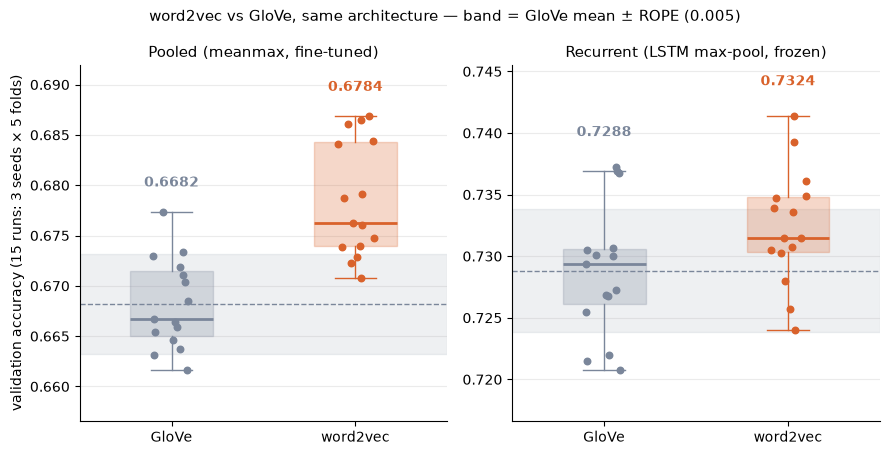

In [95]:
C = {"GloVe": "#7a869a", "word2vec": "#d9622b"}
fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
for ax, title, g, w in [(axes[0], "Pooled (meanmax, fine-tuned)", glove_p, w2v_p),
                        (axes[1], "Recurrent (LSTM max-pool, frozen)", glove_r, w2v_r)]:
    rng = np.random.default_rng(0)
    for i, (name, v) in enumerate([("GloVe", g), ("word2vec", w)]):
        ax.boxplot(v, positions=[i], widths=.45, showfliers=False, patch_artist=True,
                   boxprops=dict(facecolor=C[name], alpha=.25, edgecolor=C[name]),
                   medianprops=dict(color=C[name], lw=2),
                   whiskerprops=dict(color=C[name]), capprops=dict(color=C[name]))
        ax.scatter(i + rng.uniform(-.1, .1, len(v)), v, s=22, color=C[name], zorder=3)
        ax.text(i, v.max() + .0025, f"{v.mean():.4f}", ha="center",
                fontsize=10, color=C[name], weight="bold")
    ax.axhspan(g.mean() - .005, g.mean() + .005, color="#7a869a", alpha=.12, zorder=0)
    ax.axhline(g.mean(), color="#7a869a", lw=1, ls="--", zorder=1)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["GloVe", "word2vec"])
    ax.set_title(title, fontsize=11); ax.grid(axis="y", alpha=.25)
    ax.spines[["top", "right"]].set_visible(False)
    ax.margins(y=0.2)  
axes[0].set_ylabel("validation accuracy (15 runs: 3 seeds × 5 folds)")
fig.suptitle("word2vec vs GloVe, same architecture — band = GloVe mean ± ROPE (0.005)", fontsize=11)
fig.tight_layout()
fig.savefig("w2v_vs_glove.png", dpi=200)
plt.show()

In [107]:
for label, accs in res_wd.items():
    m, pw, pr, pb = paired_rope(accs, w2v_p)
    print(f"{label}: mean={accs.mean():.4f}  Δ vs no-dropout={m:+.4f}  "
          f"P(worse)={pw:.3f}  P(rope)={pr:.3f}  P(better)={pb:.3f}")

w2v pooled wd0.1: mean=0.6789  Δ vs no-dropout=+0.0005  P(worse)=0.030  P(rope)=0.914  P(better)=0.056
w2v pooled wd0.3: mean=0.6696  Δ vs no-dropout=-0.0088  P(worse)=0.921  P(rope)=0.079  P(better)=0.000


#### **Confusion matrices**

In [117]:
CKPTS = {                              
    "w2v_ckpt.pkl":        "pooled",
    "w2v_rnn_ckpt.pkl":    "recurrent",
    "w2v_wd_v2_ckpt.pkl":  "pooled+wd",
}
names = ["entailment", "neutral", "contradiction"]

In [118]:
def collect(path):
    """-> {system_key: (y_true, y_pred, mean_acc)} for every system in one checkpoint file."""
    with open(path, "rb") as f:
        obj = pickle.load(f)
    store = obj if isinstance(obj, dict) else next(
        v for v in vars(obj).values() if isinstance(v, dict) and any("|seed" in str(k) for k in v))
    acc_by, T, P = defaultdict(list), defaultdict(list), defaultdict(list)
    for key, rec in store.items():
        m = re.match(r"(.+)\|seed(\d+)\|fold(\d+)$", str(key))
        if not m: continue
        sk, seed, fold = m.group(1), int(m.group(2)), int(m.group(3))
        val = cv_sets[seed][fold]["validation"]
        preds = np.asarray(rec["predictions"])
        assert len(preds) == len(val), (key, len(preds), len(val))
        T[sk] += [int(lab) for (_, lab) in val]
        P[sk] += preds.tolist()
        acc_by[sk].append(rec["accuracy"])
    return {sk: (np.array(T[sk]), np.array(P[sk]), float(np.mean(acc_by[sk]))) for sk in T}

In [ ]:
models = {}                                  # nickname -> (y_true, y_pred, mean_acc)
for fn, nick in CKPTS.items():
    for sk, (t, p, a) in collect(f"{RESULTS}/{fn}").items():
        models[f"{nick} | {sk[:40]} | acc={a:.4f}"] = (t, p, a)

In [124]:
def conf(t, p):
    C = np.zeros((3, 3), int)
    for a, b in zip(t, p): C[a, b] += 1
    return C

**Nice Plot no.2**

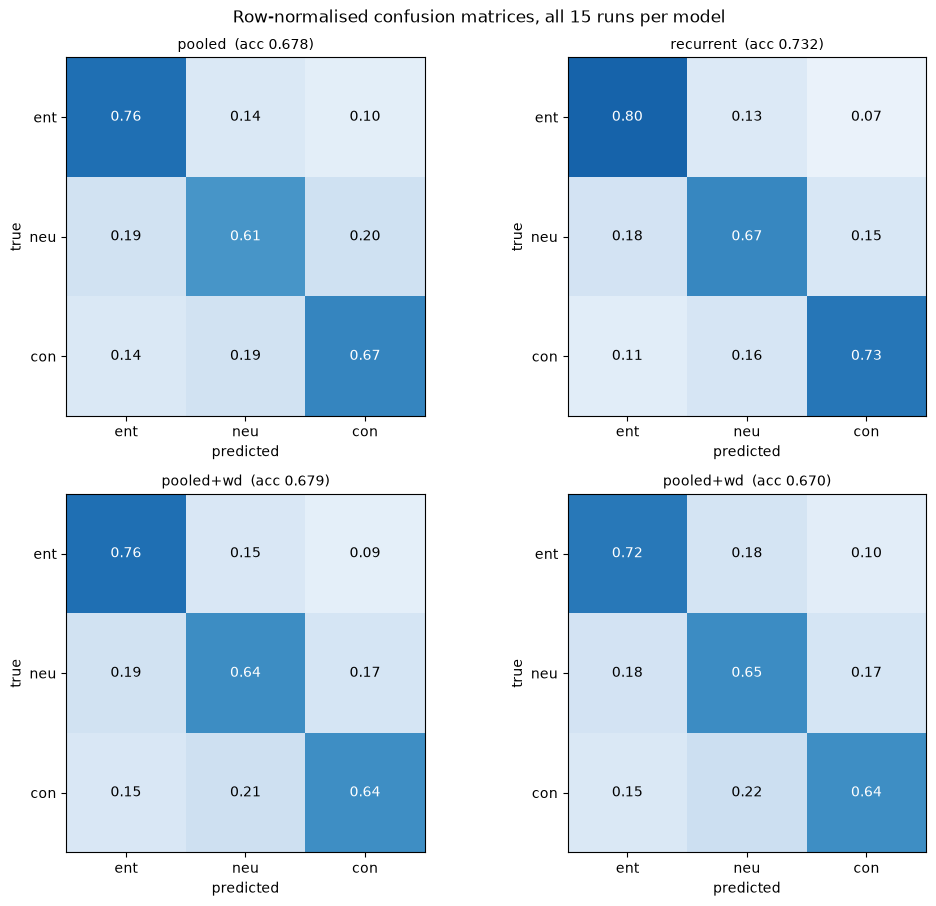


model                            entai     neutr     contr   (recall per true class)
pooled (0.678)                   0.756     0.609     0.670
recurrent (0.732)                0.802     0.666     0.729
pooled+wd (0.679)                0.756     0.641     0.639
pooled+wd (0.670)                0.721     0.648     0.639


In [125]:
n = len(models); cols = min(n, 2); rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(5.2 * cols, 4.6 * rows), squeeze=False)
for ax, (label, (t, p, a)) in zip(axes.ravel(), models.items()):
    C = conf(t, p); R = C / C.sum(1, keepdims=True)
    ax.imshow(R, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{R[i,j]:.2f}", ha="center", va="center",
                    color="white" if R[i, j] > .5 else "black", fontsize=10)
    ax.set_xticks(range(3)); ax.set_xticklabels(["ent", "neu", "con"])
    ax.set_yticks(range(3)); ax.set_yticklabels(["ent", "neu", "con"])
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(label.split(" | ")[0] + f"  (acc {a:.3f})", fontsize=10)
for ax in axes.ravel()[n:]: ax.axis("off")
fig.suptitle("Row-normalised confusion matrices, all 15 runs per model", fontsize=12)
fig.tight_layout(); plt.show()

print(f"\n{'model':28s} " + " ".join(f"{c[:5]:>9s}" for c in names) + "   (recall per true class)")
for label, (t, p, a) in models.items():
    C = conf(t, p); rec = C.diagonal() / C.sum(1)
    print(f"{label.split(' | ')[0] + f' ({a:.3f})':28s} " + " ".join(f"{r:9.3f}" for r in rec))

#### **Model Configs inspection**

In [96]:
import pprint
pprint.pprint(w2v_pooled["w2v pooled [anchor]"]["enc_cfg"])
pprint.pprint(w2v_pooled["w2v pooled [anchor]"]["opt_cfg"])

{'freeze': False, 'pool': 'meanmax', 'type': 'pool'}
{'batch_size': 256,
 'emb_lr': 0.0001,
 'learning_rate': 0.0003,
 'num_epochs': 20,
 'weight_decay': 0.0001}


In [98]:
spec = w2v_rnn["w2v lstm-maxpool [anchor]"]
pprint.pprint(spec["enc_cfg"])
pprint.pprint(spec["opt_cfg"])
print("combo:", spec["combo"])
pprint.pprint(spec["head_cfg"])

{'bi': False,
 'cell': 'lstm',
 'freeze': True,
 'hidden': 256,
 'output': 'maxpool',
 'type': 'rnn',
 'word_dropout': 0.0}
{'batch_size': 128,
 'learning_rate': 0.001,
 'num_epochs': 20,
 'weight_decay': 0.0001}
combo: nli
{'dropout': 0.1, 'hidden1': 256, 'hidden2': 256}


### **Loss Curves**

In [131]:
def find_epochs(obj):
    """Recursively find a list of {'train_metrics':..., 'val_metrics':...} dicts."""
    if isinstance(obj, list) and obj and isinstance(obj[0], dict) and "val_metrics" in obj[0]:
        return obj
    if isinstance(obj, dict):
        for v in obj.values():
            r = find_epochs(v)
            if r: return r
    elif isinstance(obj, list):
        for v in obj:
            r = find_epochs(v)
            if r: return r
    return None

In [166]:
curves = {}                                    # system folder -> (epochs list, file)
for fold_dir in sorted(Path("results_p2").rglob("fold-0")):
    if fold_dir.parent.name != "seed-0":
        continue
    system = fold_dir.parent.parent.name       # folder named after the system key
    for f in fold_dir.iterdir():
        if f.suffix in (".json", ".log", ".txt") and f.name != "model.json":
            try:
                ep = find_epochs(json.load(open(f, encoding="utf-8")))
            except Exception:
                continue
            if ep:
                curves[system] = (ep, f.name); break

print(f"found curves for {len(curves)} systems:")
for s, (ep, fn) in curves.items():
    print(f"  {len(ep):2d} epochs  {fn:20s} {s[:70]}")

found curves for 6 systems:
  20 epochs  model.run.json       pooled_random_init_232e7e97
  20 epochs  model.run.json       pooled_random_init_emb_lr1e_3_64061e86
  20 epochs  model.run.json       w2v_lstm_maxpool__anchor_25b8b85f
  20 epochs  model.run.json       w2v_pooled__anchor_36dfcdea
  20 epochs  model.run.json       w2v_pooled_wd0_1_2af13d92
  20 epochs  model.run.json       w2v_pooled_wd0_3_7c195fcb


In [172]:
# nice plot
n = len(curves); cols = min(n, 3); rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(4.6 * cols, 3.6 * rows), squeeze=False)
for ax, (system, (ep, _)) in zip(axes.ravel(), curves.items()):
    x = np.arange(1, len(ep) + 1)
    tr = [e["train_metrics"]["loss"] for e in ep]
    va = [e["val_metrics"]["loss"] for e in ep]
    ax.plot(x, tr, "--", color="#7a869a", label="train")
    ax.plot(x, va, color="#d9622b", label="validation")
    b = int(np.argmin(va)) + 1
    ax.axvline(b, color="#d9622b", alpha=.3); ax.annotate(f"best: epoch {b}", (b, min(va)),
        xytext=(6, 10), textcoords="offset points", fontsize=8)
    ax.set_title(system[:38], fontsize=9); ax.set_xlabel("epoch"); ax.set_ylabel("loss")
    ax.grid(alpha=.25); ax.spines[["top", "right"]].set_visible(False)
for ax in axes.ravel()[n:]: ax.axis("off")
axes.ravel()[0].legend(fontsize=8)
fig.suptitle("Loss curves, seed 0 fold 0", fontsize=11); fig.tight_layout(); plt.show()
#fig.suptitle("Loss curves, seed 0 fold 0", fontsize=11); fig.tight_layout(); plt.show()

C:\Users\Uzivatel\AppData\Local\Temp\ipykernel_42356\869135857.py:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.suptitle("Loss curves, seed 0 fold 0", fontsize=11); fig.tight_layout(); plt.show()


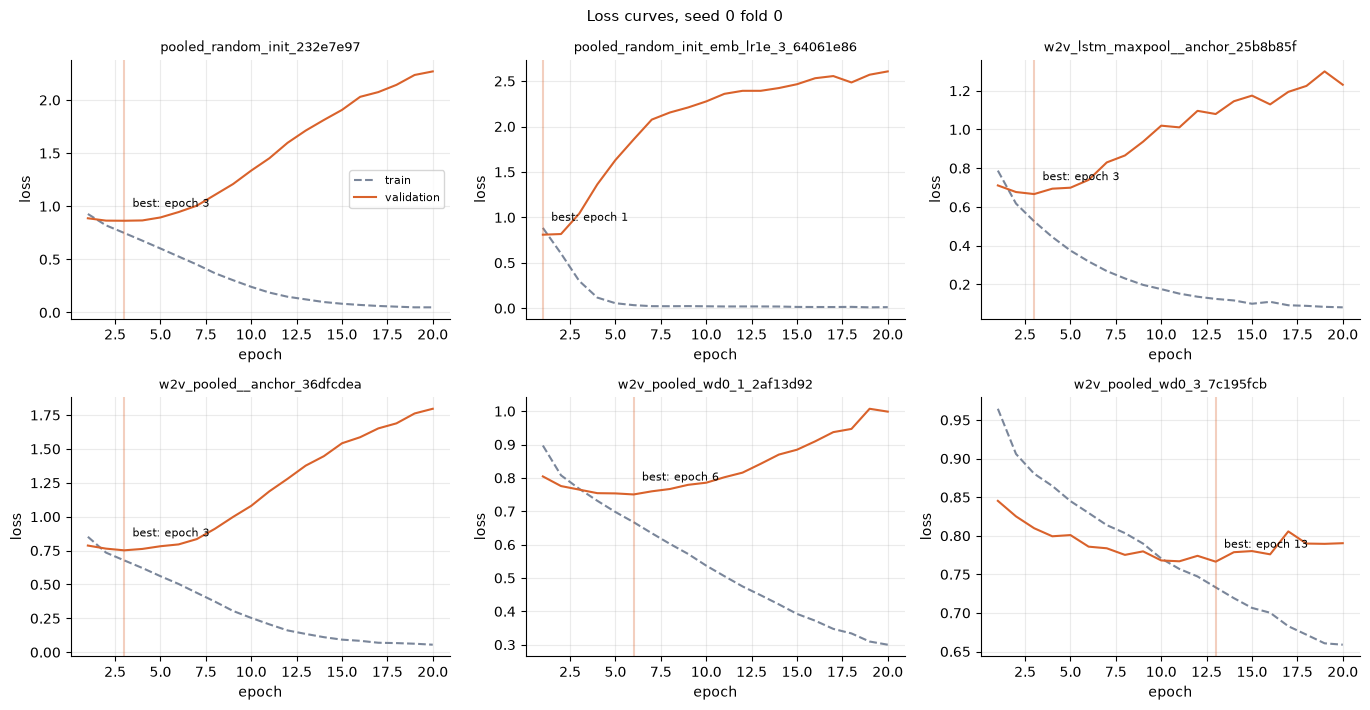

In [ ]:
%matplotlib inline
from IPython.display import display
display(fig)

### **Similarity**

Antonyms are almost as similar as synonyms in word2vec. The gap is 0.602 − 0.537 = 0.065, which is small, so the embedding barely separates “means the same” from “means the opposite”.

In [74]:
def cos(a, b): return float(V[idx[a]] @ V[idx[b]])

In [75]:
def nn(w, k=8):
    s = V @ V[idx[w]]
    return [(words[i], round(float(s[i]), 2)) for i in np.argsort(-s)[1:k+1]]

In [76]:
words, vecs = [], []
with open(W2V_TXT, encoding="utf-8") as f:
    next(f)
    for line in f:
        p = line.rstrip().split(" ")
        words.append(p[0]); vecs.append(np.asarray(p[1:], dtype=np.float32))
V = np.vstack(vecs); V /= np.linalg.norm(V, axis=1, keepdims=True)
idx = {w: i for i, w in enumerate(words)}



for w in ["dog", "man", "guitar", "running", "sleeping", "happy", "not"]:
    if w in idx: print(w, "->", nn(w))

syn = [("man","guy"),("car","automobile"),("big","large"),("small","little"),
       ("child","kid"),("woman","lady"),("sofa","couch"),("smiling","grinning")]
ant = [("sleeping","awake"),("happy","sad"),("big","small"),("hot","cold"),
       ("up","down"),("young","old"),("indoors","outdoors"),("empty","full"),
       ("inside","outside"),("sitting","standing"),("day","night"),("man","woman")]
rnd = random.Random(0)
vocab_pool = [w for w in words if w.isalpha()]
rand = [(rnd.choice(vocab_pool), rnd.choice(vocab_pool)) for _ in range(500)]

def mean_cos(pairs):
    s = [cos(a, b) for a, b in pairs if a in idx and b in idx]
    return np.mean(s), len(s)

for name, p in [("synonyms", syn), ("antonyms", ant), ("random", rand)]:
    m, n = mean_cos(p); print(f"{name:9s} mean cos = {m:.3f}  (n={n})")

dog -> [('dogs', 0.87), ('puppy', 0.81), ('pooch', 0.76), ('cat', 0.76), ('beagle', 0.74), ('Pomeranian', 0.72), ('canines', 0.72), ('chihuahua', 0.72)]
man -> [('woman', 0.77), ('boy', 0.68), ('teenager', 0.66), ('girl', 0.59), ('robber', 0.56), ('men', 0.55), ('guy', 0.54), ('person', 0.53)]
guitar -> [('guitars', 0.84), ('mandolin', 0.78), ('harmonica', 0.77), ('saxophone', 0.77), ('sax', 0.75), ('banjo', 0.75), ('guitarist', 0.75), ('guitarists', 0.74)]
running -> [('Running', 0.7), ('ran', 0.61), ('run', 0.61), ('rushing', 0.45), ('sprinting', 0.43), ('coming', 0.42), ('trotting', 0.41), ('going', 0.41)]
sleeping -> [('slept', 0.74), ('sleep', 0.71), ('asleep', 0.63), ('snoozing', 0.62), ('sleeps', 0.6), ('bed', 0.57), ('dozing', 0.56), ('napping', 0.55)]
happy -> [('glad', 0.74), ('ecstatic', 0.66), ('proud', 0.64), ('delighted', 0.63), ('disappointed', 0.63), ('excited', 0.62), ('elated', 0.62), ('unhappy', 0.61)]
not -> [('do', 0.71), ('did', 0.69), ('anymore', 0.67), ('anythin

word2vec groups words by category and morphology (dog: puppy, beagle; guitar: banjo, mandolin; sleeping: slept, asleep), which supports paraphrase and hypernym matches in SNLI. However, antonyms and contrasts are also close neighbors (happy: unhappy 0.61, disappointed 0.63; man: woman 0.77), and ‘not’ has no negation-specific neighbors (do, did, does). So contradiction cues must be learned from labels, not read from the embedding. Mean cosine for antonym pairs (0.54) is close to synonym pairs (0.60).

In [110]:
# ---- pair groups ----
syn = [("man","guy"),("car","automobile"),("big","large"),("small","little"),
       ("child","kid"),("woman","lady"),("sofa","couch"),("smiling","grinning"),
       ("shirt","top"),("road","street"),("jump","leap"),("shout","yell")]
ant = [("sleeping","awake"),("happy","sad"),("big","small"),("hot","cold"),
       ("up","down"),("young","old"),("indoors","outdoors"),("empty","full"),
       ("inside","outside"),("sitting","standing"),("day","night"),("open","closed"),
       ("wet","dry"),("light","dark"),("fast","slow")]
contrast = [("man","woman"),("boy","girl"),("father","mother"),("he","she")]

# ---- random baseline: 2000 random pairs from alphabetic words ----
rng = random.Random(0)
pool = [w for w in words if w.isalpha() and w.islower()]
rand = np.array([cos(rng.choice(pool), rng.choice(pool)) for _ in range(2000)])

def report(name, pairs, show=True):
    ok = [(a, b) for a, b in pairs if a in idx and b in idx]
    miss = [(a, b) for a, b in pairs if (a, b) not in ok]
    s = np.array([cos(a, b) for a, b in ok])
    print(f"\n{name}: mean={s.mean():.3f}  min={s.min():.3f}  max={s.max():.3f}  n={len(s)}"
          + (f"  (missing: {miss})" if miss else ""))
    if show:
        for (a, b), v in sorted(zip(ok, s), key=lambda t: -t[1]):
            print(f"   {a:10s} {b:10s} {v:.2f}")
    return s

s_syn  = report("synonyms", syn)
s_ant  = report("antonyms", ant)
s_con  = report("contrast (gender etc.)", contrast)

print(f"\nrandom pairs: mean={rand.mean():.3f}  std={rand.std():.3f}  "
      f"95th percentile={np.percentile(rand, 95):.3f}  n={len(rand)}")

# ---- how antonyms compare with chance ----
print(f"\nantonym mean ({s_ant.mean():.3f}) is above "
      f"{(rand < s_ant.mean()).mean()*100:.1f}% of random pairs")
print(f"synonym - antonym gap = {s_syn.mean() - s_ant.mean():.3f}   "
      f"antonym - random gap = {s_ant.mean() - rand.mean():.3f}")


synonyms: mean=0.566  min=0.088  max=0.841  n=12
   smiling    grinning   0.84
   sofa       couch      0.83
   shout      yell       0.77
   jump       leap       0.66
   woman      lady       0.63
   car        automobile 0.58
   big        large      0.56
   man        guy        0.54
   child      kid        0.48
   road       street     0.46
   small      little     0.36
   shirt      top        0.09

antonyms: mean=0.529  min=0.207  max=0.696  n=15
   inside     outside    0.70
   wet        dry        0.68
   indoors    outdoors   0.64
   up         down       0.64
   open       closed     0.58
   sitting    standing   0.57
   happy      sad        0.54
   fast       slow       0.53
   day        night      0.51
   sleeping   awake      0.50
   big        small      0.50
   light      dark       0.47
   hot        cold       0.46
   young      old        0.42
   empty      full       0.21

contrast (gender etc.): mean=0.756  min=0.613  max=0.854  n=4
   boy        girl       0.

###  Other

In [147]:
import random, re
import numpy as np, pandas as pd
from collections import Counter, defaultdict
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# ---------- 0) vectors from the subset file (header "N 300", then "word v1 ... v300") ----------
def load_vectors(path):
    words, vecs = [], []
    with open(path, encoding="utf-8") as f:
        next(f)
        for line in f:
            p = line.rstrip().split(" ")
            words.append(p[0]); vecs.append(np.asarray(p[1:], dtype=np.float32))
    V = np.vstack(vecs); V = V / np.linalg.norm(V, axis=1, keepdims=True)
    return words, V, {w: i for i, w in enumerate(words)}

# ---------- 1) WordNet relation pairs (synonym, antonym, hypernym, co-hyponym, random) ----------
def build_relation_pairs(vocab_words, wn, max_per_relation=500, per_word_cap=5, seed=0):
    rng = random.Random(seed); vocab = set(vocab_words)
    rel = defaultdict(set)
    ok = lambda w: w in vocab and "_" not in w
    for w in sorted(vocab):
        for syn in wn.synsets(w):
            names = [l.name().lower() for l in syn.lemmas()]
            for l in syn.lemmas():
                if l.name().lower() != w: continue
                for a in l.antonyms():
                    if ok(a.name().lower()): rel["antonym"].add((w, a.name().lower()))
            for n in names:
                if n != w and ok(n): rel["synonym"].add(tuple(sorted((w, n))))
            for h in syn.hypernyms():
                for hl in h.lemmas():
                    if ok(hl.name().lower()): rel["hypernym"].add((w, hl.name().lower()))
                for sib in h.hyponyms():                          # co-hyponyms share a direct hypernym
                    for sl in sib.lemmas():
                        n = sl.name().lower()
                        if n != w and ok(n) and sib != syn: rel["co_hyponym"].add(tuple(sorted((w, n))))
    out = {}
    for r, pairs in rel.items():
        pairs = sorted(pairs); rng.shuffle(pairs)
        cnt, kept = Counter(), []
        for a, b in pairs:                                        # at most per_word_cap pairs per word
            if cnt[a] < per_word_cap and cnt[b] < per_word_cap:
                kept.append((a, b)); cnt[a] += 1; cnt[b] += 1
            if len(kept) >= max_per_relation: break
        out[r] = kept
    vw = sorted(vocab)
    out["random"] = [(rng.choice(vw), rng.choice(vw)) for _ in range(max_per_relation)]
    return out

def cosine_by_relation(pairs_by_rel, V, idx):
    rows = []
    for r, ps in pairs_by_rel.items():
        c = np.array([float(V[idx[a]] @ V[idx[b]]) for a, b in ps])
        rows.append({"relation": r, "n": len(c), "mean": c.mean(), "median": np.median(c)})
    return pd.DataFrame(rows).sort_values("mean", ascending=False).round(3)

# ---------- 2) relation probe: [u, v, |u-v|, u*v] vs cosine-only, word-disjoint train/test ----------
def run_probe(pairs_by_rel, V, idx, seed=0, test_frac=0.3):
    rels = sorted(pairs_by_rel); m = min(len(pairs_by_rel[r]) for r in rels)
    rng = random.Random(seed)
    data = [(a, b, r) for r in rels for a, b in rng.sample(pairs_by_rel[r], m)]        # balanced classes
    allw = sorted({w for a, b, _ in data for w in (a, b)}); rng.shuffle(allw)
    test_w = set(allw[: int(len(allw) * test_frac)])
    tr = [d for d in data if d[0] not in test_w and d[1] not in test_w]
    te = [d for d in data if d[0] in test_w and d[1] in test_w]                          # cross-word pairs dropped
    def feats(ds, full):
        u = np.stack([V[idx[a]] for a, _, _ in ds]); v = np.stack([V[idx[b]] for _, b, _ in ds])
        return np.hstack([u, v, np.abs(u - v), u * v]) if full else (u * v).sum(1, keepdims=True)
    y_tr = [d[2] for d in tr]; y_te = [d[2] for d in te]; res = {}
    for name, full in [("full [u,v,|u-v|,u*v]", True), ("cosine only", False)]:
        clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
        clf.fit(feats(tr, full), y_tr); p = clf.predict(feats(te, full))
        res[name] = {"accuracy": round(accuracy_score(y_te, p), 4), "macro_f1": round(f1_score(y_te, p, average="macro"), 4),
                     "confusion": confusion_matrix(y_te, p, labels=rels)}
    return res, rels, len(tr), len(te)

# ---------- 3) sentence-level geometry by gold label ----------
def sentence_diagnostics(pairs, tokenizer, V, idx):
    cos, soft = defaultdict(list), defaultdict(list)
    for (p, h), lab in pairs:
        P = [idx[t] for t in tokenizer.tokens(p) if t in idx]; H = [idx[t] for t in tokenizer.tokens(h) if t in idx]
        if not P or not H: continue
        mp, mh = V[P].mean(0), V[H].mean(0)
        cos[int(lab)].append(float(mp @ mh / (np.linalg.norm(mp) * np.linalg.norm(mh))))
        soft[int(lab)].append(float((V[H] @ V[P].T).max(1).mean()))                    # best premise match per hypothesis word
    return pd.DataFrame({"label": ["entailment", "neutral", "contradiction"],
                         "cosine (mean vectors)": [np.mean(cos[k]) for k in (0, 1, 2)],
                         "soft-overlap": [np.mean(soft[k]) for k in (0, 1, 2)],
                         "n": [len(cos[k]) for k in (0, 1, 2)]}).round(3)

# ---------- 4) gender direction ----------
def gender_projection(words_to_test, V, idx):
    pairs = [("he","she"),("man","woman"),("boy","girl"),("father","mother"),("son","daughter"),("his","her")]
    g = np.mean([V[idx[a]] - V[idx[b]] for a, b in pairs if a in idx and b in idx], axis=0); g /= np.linalg.norm(g)
    proj = sorted([(w, float(V[idx[w]] @ g)) for w in words_to_test if w in idx], key=lambda t: t[1])
    return proj                                                                          # negative = she-leaning

In [158]:
import nltk; nltk.download("wordnet"); nltk.download("omw-1.4")
from nltk.corpus import wordnet as wn, stopwords
from collections import Counter

words, V, idx = load_vectors("word2vec/w2v_snli_subset.300d.txt")

# frequent SNLI content words that have a vector (lowercase, alphabetic, not a stopword)
stop = set(stopwords.words("english"))
freq = Counter(t for (p, h), _ in working_set for t in tok_nopunct.tokens(p) + tok_nopunct.tokens(h))
content = [w for w, n in freq.items() if n >= 3 and w.isalpha() and w not in stop and w in idx]
print(len(content), "content words")

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Uzivatel\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Uzivatel\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


6993 content words


In [161]:
pairs_by_rel = build_relation_pairs(content, wn, max_per_relation=500, per_word_cap=5, seed=0)
print({k: len(v) for k, v in pairs_by_rel.items()})
print(cosine_by_relation(pairs_by_rel, V, idx))

{'hypernym': 500, 'co_hyponym': 500, 'synonym': 500, 'antonym': 411, 'random': 500}
     relation    n   mean  median
3     antonym  411  0.415   0.383
2     synonym  500  0.278   0.207
0    hypernym  500  0.173   0.151
1  co_hyponym  500  0.117   0.095
4      random  500  0.074   0.063


In [160]:
res, rels, n_tr, n_te = run_probe(pairs_by_rel, V, idx)
print("classes:", rels, "| train", n_tr, "test", n_te)
for k, v in res.items():
    print(k, {m: v[m] for m in ("accuracy", "macro_f1")}); print(v["confusion"])

classes: ['antonym', 'co_hyponym', 'hypernym', 'random', 'synonym'] | train 1049 test 190
full [u,v,|u-v|,u*v] {'accuracy': 0.4211, 'macro_f1': 0.4355}
[[17  2  4  0  5]
 [ 0 10 11  5 13]
 [ 4  5 14  5  6]
 [ 0  9  8 23  6]
 [ 3 10  9  5 16]]
cosine only {'accuracy': 0.3789, 'macro_f1': 0.3573}
[[18  0  0  0 10]
 [ 3 13  4 14  5]
 [ 5 14  3  5  7]
 [ 1 13  3 27  2]
 [12 12  2  6 11]]


In [153]:
print(sentence_diagnostics(working_set, tok_nopunct, V, idx))

           label  cosine (mean vectors)  soft-overlap      n
0     entailment                  0.719         0.715  13354
1        neutral                  0.692         0.602  13306
2  contradiction                  0.655         0.568  13339


In [154]:
test_words = ["cooking","cleaning","nursing","shopping","dancing","teaching","driving",
              "building","fighting","working","coaching","beautiful","strong","gentle"]
for w, s in gender_projection(test_words, V, idx): print(f"{w:10s} {s:+.3f}")

beautiful  -0.203
nursing    -0.172
shopping   -0.170
cooking    -0.115
dancing    -0.113
teaching   -0.069
cleaning   -0.049
building   -0.016
gentle     -0.007
driving    +0.004
working    +0.009
strong     +0.035
fighting   +0.077
coaching   +0.129


# Full Dataset W2V LSTM

In [135]:
spec = copy.deepcopy(SW.best_specs()["recurrent"])
spec["emb_key"], spec["tok_key"] = "w2v", "w2v"

# 1) train / early-stopping split of the 40k (stratified; 10% held out)
labels = [lab for _, lab in working_set]
tr_idx, ho_idx = train_test_split(np.arange(len(working_set)), test_size=0.10,
                                  stratify=labels, random_state=0)
train_set = [working_set[i] for i in tr_idx]
hold_set  = [working_set[i] for i in ho_idx]

# 2) train; the best epoch is chosen by loss on the held-out slice, test is not used
torch.manual_seed(0); np.random.seed(0)
SAVE = "results_p2/final_w2v_recurrent_40k"
metrics, best = PP.train(train_set, hold_set, tok, emb_w2v,
                         spec["enc_cfg"], spec["combo"], spec["head_cfg"], spec["opt_cfg"],
                         3, device=device, save_to=SAVE, verbose=True)
print("best epoch:", best + 1, "| held-out acc:", round(metrics[best]["val_metrics"]["accuracy"], 4))

# 3) evaluate ONCE on the test split with the best-epoch weights
model = PP.load(SAVE, emb_w2v, device=device).to(device)
pad = emb_w2v.vocab.index(emb_w2v.pad_token); unk = emb_w2v.vocab.default_index
dl = DataLoader(PP.PairCorpus(test_pairs, tok, unk, joined=False, sep_id=unk),
                batch_size=256, shuffle=False, collate_fn=PP.make_collate(pad))
out = PP.evaluate(model, dl, torch.nn.NLLLoss(), device)

y_pred = np.concatenate(out["predictions"]); y_true = np.concatenate(out["labels"])
print(f"\nTEST  n={len(y_true)}  acc={out['accuracy']:.4f}  "
      f"macro-F1={f1_score(y_true, y_pred, average='macro'):.4f}")
print(confusion_matrix(y_true, y_pred))

        epoch  1/20 | train loss 0.783 acc 0.656 | val loss 0.681 acc 0.721 |  37.3s  <- best
        epoch  2/20 | train loss 0.621 acc 0.746 | val loss 0.656 acc 0.732 |  40.2s  <- best
        epoch  3/20 | train loss 0.528 acc 0.791 | val loss 0.640 acc 0.744 |  42.8s  <- best
        epoch  4/20 | train loss 0.450 acc 0.826 | val loss 0.663 acc 0.748 |  44.7s
        epoch  5/20 | train loss 0.388 acc 0.852 | val loss 0.682 acc 0.753 |  42.9s
        epoch  6/20 | train loss 0.332 acc 0.874 | val loss 0.723 acc 0.746 |  37.2s
        epoch  7/20 | train loss 0.282 acc 0.896 | val loss 0.777 acc 0.743 |  37.1s
        epoch  8/20 | train loss 0.244 acc 0.910 | val loss 0.817 acc 0.741 |  36.1s
        epoch  9/20 | train loss 0.210 acc 0.923 | val loss 0.895 acc 0.735 |  36.4s
        epoch 10/20 | train loss 0.191 acc 0.930 | val loss 0.943 acc 0.726 |  37.4s
        epoch 11/20 | train loss 0.173 acc 0.936 | val loss 0.956 acc 0.740 |  36.1s
        epoch 12/20 | train loss 0.144

In [136]:
OUT = "results_p2/final_w2v_recurrent_40k"    

In [139]:
# 1) per-epoch training curves (train and held-out validation)
curves = pd.DataFrame({
    "epoch":      np.arange(1, len(metrics) + 1),
    "train_loss": [e["train_metrics"]["loss"] for e in metrics],
    "train_acc":  [e["train_metrics"]["accuracy"] for e in metrics],
    "val_loss":   [e["val_metrics"]["loss"] for e in metrics],
    "val_acc":    [e["val_metrics"]["accuracy"] for e in metrics],
})
curves["is_best"] = curves["epoch"] == best + 1
curves.to_csv(f"{OUT}_curves.csv", index=False)

# 2) per-example test predictions
y_true_a, y_pred_a = np.asarray(y_true), np.asarray(y_pred)
pred = pd.DataFrame({
    "premise":    [p for (p, h), _ in test_pairs],
    "hypothesis": [h for (p, h), _ in test_pairs],
    "gold":       y_true_a, "pred": y_pred_a,
    "correct":    (y_true_a == y_pred_a).astype(int),
})
assert len(pred) == len(y_true_a), "test_pairs and predictions differ in length"
pred.to_csv(f"{OUT}_test_predictions.csv", index=False)

# 3) summary: config, best epoch, test scores, confusion matrix
summary = {
    "model": "word2vec LSTM max-over-states, trained on 40k (10% held out for early stopping)",
    "spec": {k: spec[k] for k in ("enc_cfg", "combo", "head_cfg", "opt_cfg")},
    "best_epoch": int(best + 1),
    "heldout_acc_at_best": float(metrics[best]["val_metrics"]["accuracy"]),
    "test_n": int(len(y_true_a)),
    "test_acc": float((y_true_a == y_pred_a).mean()),
    "test_macro_f1": float(f1_score(y_true_a, y_pred_a, average="macro")),
    "label_order": names,
    "confusion": confusion_matrix(y_true_a, y_pred_a).tolist(),
    "per_class": classification_report(y_true_a, y_pred_a, target_names=names,
                                       output_dict=True),
}
json.dump(summary, open(f"{OUT}_summary.json", "w"), indent=2)

print("saved:", [f"{OUT}{s}" for s in ("_curves.csv", "_test_predictions.csv", "_summary.json")])
print(f"test acc={summary['test_acc']:.4f}  macro-F1={summary['test_macro_f1']:.4f}  best epoch={best+1}")

saved: ['results_p2/final_w2v_recurrent_40k_curves.csv', 'results_p2/final_w2v_recurrent_40k_test_predictions.csv', 'results_p2/final_w2v_recurrent_40k_summary.json']
test acc=0.7505  macro-F1=0.7487  best epoch=3


In [ ]:
NA, NB = "pooled", "recurrent"

# ---------- predictions of one system from a checkpoint ----------
def load_preds(path, pick=None):
    obj = pickle.load(open(path, "rb"))
    store = obj if isinstance(obj, dict) else next(
        v for v in vars(obj).values() if isinstance(v, dict) and any("|seed" in str(k) for k in v))
    systems = defaultdict(dict)
    for key, rec in store.items():
        m = re.match(r"(.+)\|seed(\d+)\|fold(\d+)$", str(key))
        if m: systems[m.group(1)][(int(m.group(2)), int(m.group(3)))] = np.asarray(rec["predictions"])
    return systems[pick if pick else next(iter(systems))]

def to_frame(preds, name):
    rows = []
    for (seed, fold), p in preds.items():
        val = cv_sets[seed][fold]["validation"]
        assert len(val) == len(p)
        for pos, (((pr, hy), lab), pd_) in enumerate(zip(val, p)):
            rows.append((seed, fold, pos, pr, hy, int(lab), int(pd_)))
    df = pd.DataFrame(rows, columns=["seed","fold","pos","premise","hypothesis","gold",f"pred_{name}"])
    df[f"ok_{name}"] = (df.gold == df[f"pred_{name}"]).astype(int)
    return df

# ---------- hand-built features ----------
tok = lambda s: re.findall(r"[a-z0-9']+", s.lower())
NEG = {"no","not","never","nobody","nothing","nowhere","none","neither","nor","cannot"}
NUMW = {"one","two","three","four","five","six","seven","eight","nine","ten","several","many","few","couple"}
MALE = {"man","men","boy","boys","he","his","him","father","guy","guys","gentleman","male","son","husband"}
FEMALE = {"woman","women","girl","girls","she","her","mother","lady","ladies","female","daughter","wife"}
ANT = [("sleeping","awake"),("happy","sad"),("big","small"),("hot","cold"),("up","down"),("young","old"),
       ("indoors","outdoors"),("inside","outside"),("sitting","standing"),("day","night"),("empty","full"),
       ("open","closed"),("wet","dry"),("light","dark"),("fast","slow"),("sleeping","running"),
       ("walking","sitting"),("dog","cat"),("swimming","running")]

def feats(p, h):
    P, H = tok(p), tok(h); sP, sH = set(P), set(H)
    nums_p = {w for w in sP if w in NUMW or w.isdigit()}; nums_h = {w for w in sH if w in NUMW or w.isdigit()}
    return {
        "hyp_len": len(H), "prem_len": len(P),
        "overlap": len(sH & sP) / max(len(sH), 1),            # share of hypothesis words found in the premise
        "negation": int(any(w in NEG or w.endswith("n't") for w in H)),
        "number_mismatch": int(bool(nums_h) and nums_h != nums_p),
        "gender_swap": int(bool((sP & MALE and sH & FEMALE and not sH & MALE) or
                                (sP & FEMALE and sH & MALE and not sH & FEMALE))),
        "antonym_pair": int(any((a in sP and b in sH) or (b in sP and a in sH) for a, b in ANT)),
    }

def merge_systems(a, b):
    m = a.merge(b[["seed","fold","pos","pred_"+NB,"ok_"+NB]], on=["seed","fold","pos"])
    g = m.groupby(["premise","hypothesis","gold"], as_index=False)[["ok_"+NA,"ok_"+NB]].mean()
    return pd.concat([g, pd.DataFrame([feats(p, h) for p, h in zip(g.premise, g.hypothesis)])], axis=1)

def bins(df):
    d = df.copy()
    d["hyp_len_bin"]  = pd.cut(d.hyp_len,  [0,4,7,10,100], labels=["<=4","5-7","8-10",">10"])
    d["overlap_bin"]  = pd.cut(d.overlap,  [-.01,.2,.5,.8,1.0], labels=["<=.2",".2-.5",".5-.8",">.8"])
    d["prem_len_bin"] = pd.cut(d.prem_len, [0,8,12,18,200], labels=["<=8","9-12","13-18",">18"])
    d["label"] = d.gold.map({0:"entailment", 1:"neutral", 2:"contradiction"})   # check label ids
    return d

def table(d, col, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed); rows = []
    for v, g in d.groupby(col, observed=True):
        a, b = g["ok_"+NA].to_numpy(), g["ok_"+NB].to_numpy(); diff = b - a
        boots = [diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(n_boot)]
        rows.append({"feature": col.replace("_bin",""), "value": v, "n": len(g), NA: a.mean(), NB: b.mean(),
                     "diff": diff.mean(), "ci_lo": np.percentile(boots, 2.5), "ci_hi": np.percentile(boots, 97.5)})
    return pd.DataFrame(rows)

39999 unique pairs | accuracy: 0.6784 0.7324
        feature         value     n  pooled  recurrent  diff  ci_lo  ci_hi
          label contradiction 13338   0.670      0.729 0.060  0.054  0.065
          label    entailment 13355   0.756      0.802 0.045  0.040  0.050
          label       neutral 13306   0.609      0.666 0.057  0.051  0.063
        hyp_len           <=4  5723   0.746      0.786 0.040  0.032  0.048
        hyp_len           5-7 18352   0.680      0.736 0.057  0.052  0.062
        hyp_len          8-10 10419   0.647      0.703 0.056  0.050  0.063
        hyp_len           >10  5505   0.664      0.718 0.055  0.046  0.065
       prem_len           <=8  8617   0.681      0.743 0.062  0.055  0.068
       prem_len          9-12 13666   0.680      0.734 0.055  0.050  0.060
       prem_len         13-18 11816   0.682      0.732 0.050  0.044  0.056
       prem_len           >18  5900   0.666      0.714 0.049  0.039  0.058
        overlap          <=.2  6678   0.692      0.732 

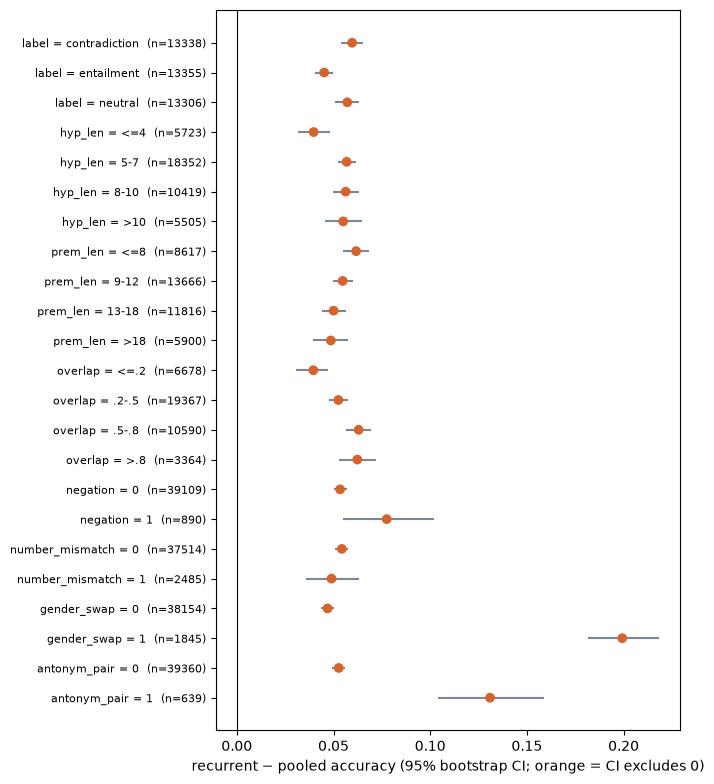

In [ ]:
pooled    = to_frame(load_preds("results_p2/w2v_ckpt.pkl"),     NA)
recurrent = to_frame(load_preds("results_p2/w2v_rnn_ckpt.pkl"), NB)
df = bins(merge_systems(pooled, recurrent))
print(len(df), "unique pairs | accuracy:", df["ok_"+NA].mean().round(4), df["ok_"+NB].mean().round(4))

cols = ["label","hyp_len_bin","prem_len_bin","overlap_bin","negation","number_mismatch","gender_swap","antonym_pair"]
T = pd.concat([table(df, c) for c in cols], ignore_index=True)
pd.set_option("display.width", 160); print(T.round(3).to_string(index=False))

T["lab"] = T.feature + " = " + T.value.astype(str) + "  (n=" + T.n.astype(str) + ")"
Tp = T[T.n >= 30].iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 0.28 * len(Tp) + 1.5))
sig = (Tp.ci_lo > 0) | (Tp.ci_hi < 0)
ax.errorbar(Tp["diff"], range(len(Tp)), xerr=[Tp["diff"] - Tp.ci_lo, Tp.ci_hi - Tp["diff"]], fmt="none", ecolor="#7a869a")
ax.scatter(Tp["diff"], range(len(Tp)), c=np.where(sig, "#d9622b", "#7a869a"), zorder=3)
ax.axvline(0, color="k", lw=.8); ax.set_yticks(range(len(Tp))); ax.set_yticklabels(Tp.lab, fontsize=8)
ax.set_xlabel("recurrent − pooled accuracy (95% bootstrap CI; orange = CI excludes 0)")
fig.tight_layout(); plt.show()

In [142]:
for f in ["gender_swap", "antonym_pair"]:
    print(f, df[df[f] == 1].label.value_counts(normalize=True).round(3).to_dict())
print("overall", df.label.value_counts(normalize=True).round(3).to_dict())

gender_swap {'contradiction': 0.788, 'neutral': 0.116, 'entailment': 0.096}
antonym_pair {'contradiction': 0.837, 'neutral': 0.091, 'entailment': 0.072}
overall {'entailment': 0.334, 'contradiction': 0.333, 'neutral': 0.333}


ok


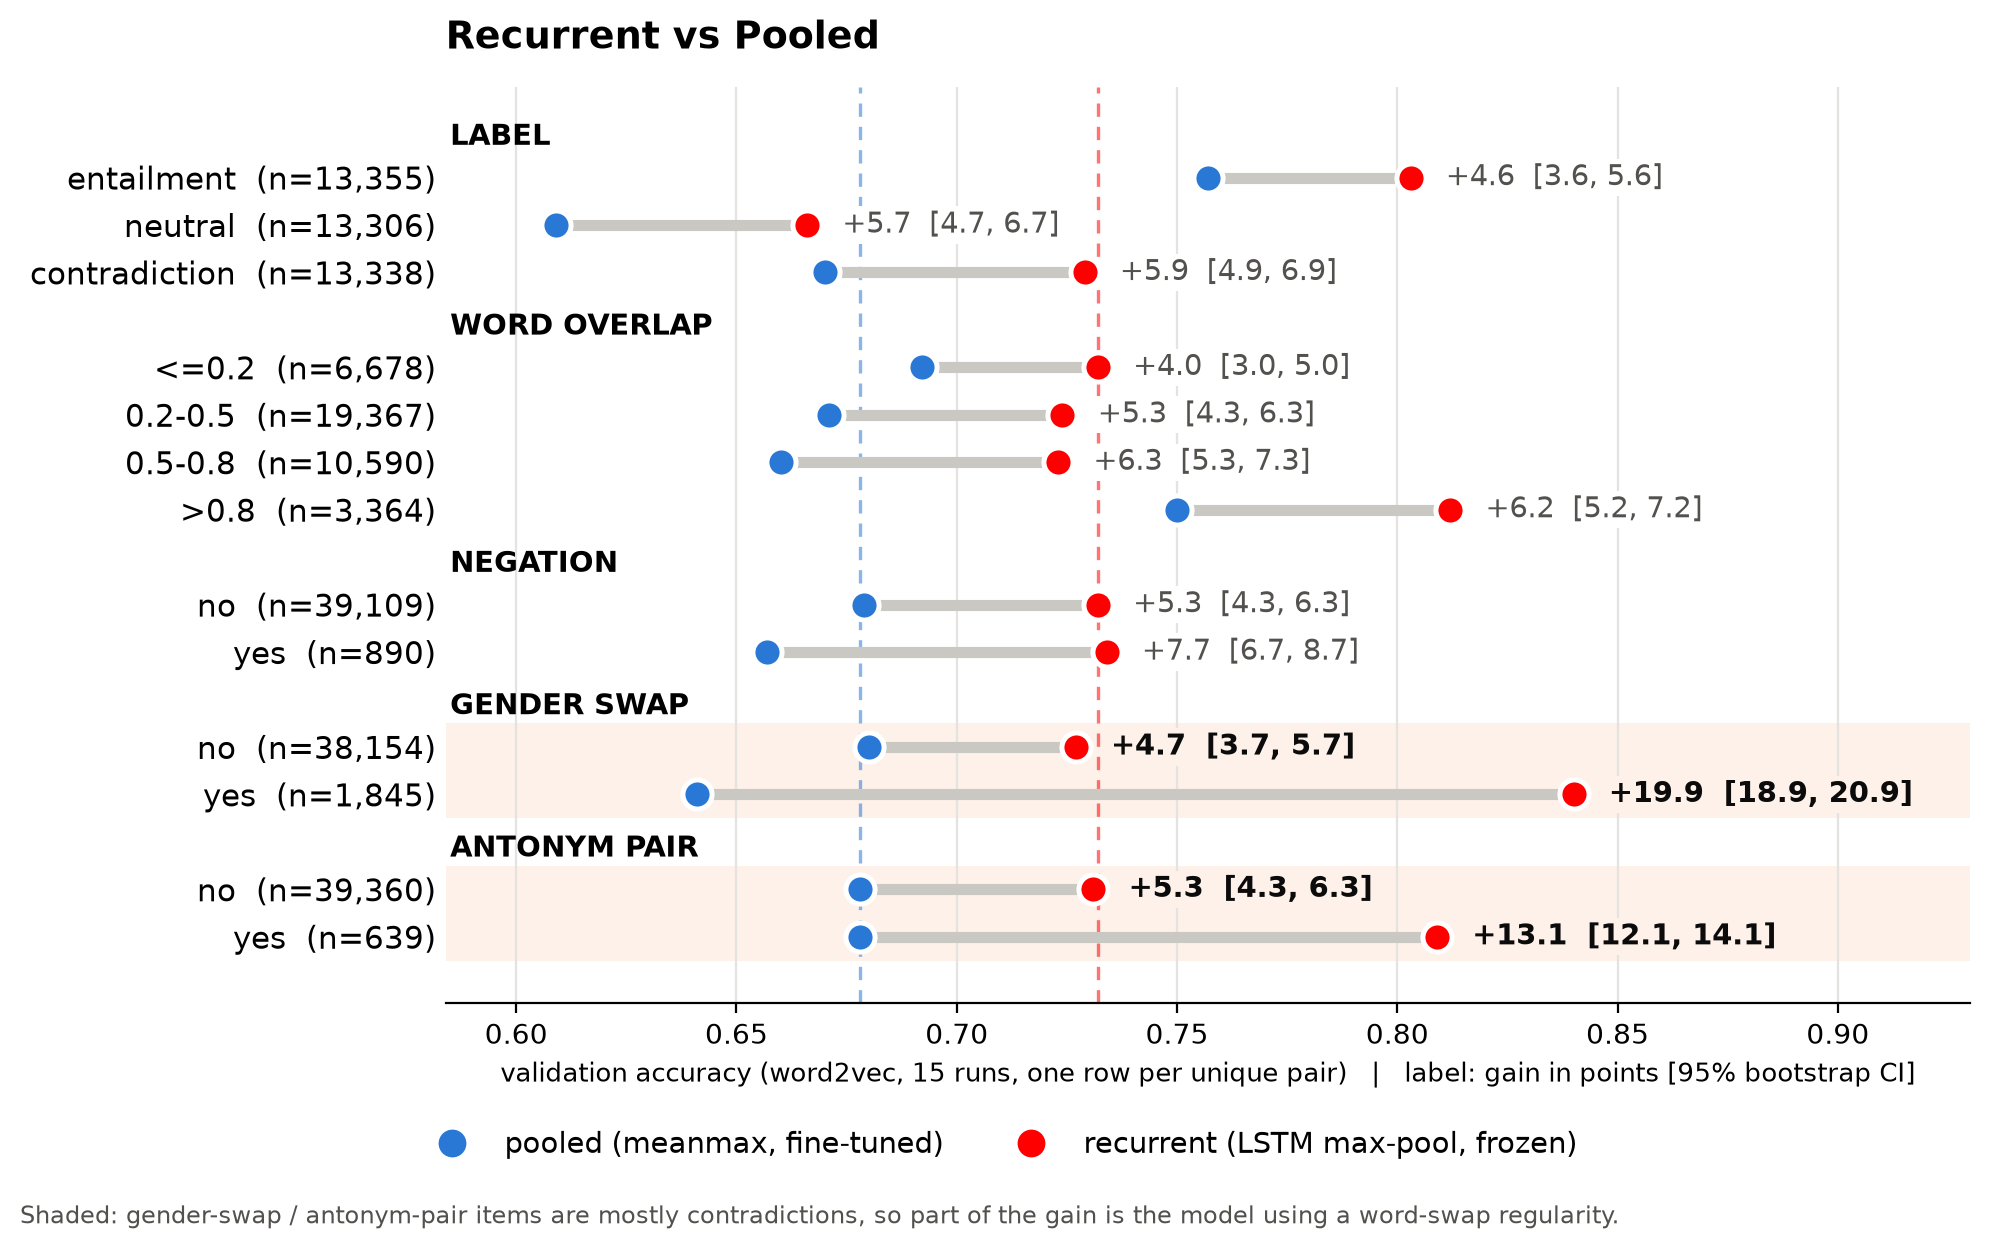

In [ ]:
from matplotlib.lines import Line2D
BLUE, ORANGE, INK, MUTED, GRID, HI = "#2a78d6", "red", "#0b0b0b", "#52514e", "#e4e3df", "#fdf1ea"
NAMES = {"label": "Label", "overlap": "Word overlap", "negation": "Negation",
         "gender_swap": "Gender swap", "antonym_pair": "Antonym pair"}
KEEP = ["label", "overlap", "negation", "gender_swap", "antonym_pair"]
CUES = {"gender_swap", "antonym_pair"}
VAL = {"0": "no", "1": "yes"}; LAB = {"0": "entailment", "1": "neutral", "2": "contradiction"}

def _name(f, v):
    v = str(v)
    return LAB.get(v, v) if f == "label" else VAL.get(v, v)

def dumbbell_slide(T, overall=(None, None), fname="fig_task6_slide.png", keep=KEEP):
    """T columns: feature, value, n, pooled, recurrent, ci_lo, ci_hi (ci on recurrent-pooled gap, as in table())."""
    T = T[T.feature.isin(keep)]
    order = {f: i for i, f in enumerate(keep)}
    T = T.assign(_o=T.feature.map(order)).sort_values("_o", kind="stable")
    fig, ax = plt.subplots(figsize=(10, 6.2), dpi=200)
    y, ticks, labels, heads, spans = 0, [], [], [], []
    for f in dict.fromkeys(T.feature):
        sub = T[T.feature == f]; y0 = y
        heads.append((NAMES[f], y - .85))
        for _, r in sub.iterrows():
            p, q = r["pooled"], r["recurrent"]
            ax.plot([p, q], [y, y], color="#c9c8c2", lw=4, solid_capstyle="round", zorder=1)
            ax.scatter([p], [y], s=110, color=BLUE, zorder=3, edgecolor="white", linewidth=1.8)
            ax.scatter([q], [y], s=110, color=ORANGE, zorder=3, edgecolor="white", linewidth=1.8)
            g = (q - p) * 100
            txt = f"+{g:.1f}" + (f"  [{r['ci_lo']*100:.1f}, {r['ci_hi']*100:.1f}]" if "ci_lo" in r else "")
            ax.text(max(p, q) + .008, y, txt, va="center", fontsize=10.5, color=INK if f in CUES else MUTED,
                    weight="bold" if f in CUES else "normal",
                    bbox=dict(fc="white" if f not in CUES else HI, ec="none", pad=1.5), zorder=4)
            ticks.append(y); labels.append(f"{_name(f, r['value'])}  (n={int(r['n']):,})"); y += 1
        spans.append((f, y0 - .5, y - .5)); y += 1.0
    for f, a, b in spans:
        if f in CUES: ax.axhspan(a, b, color=HI, zorder=0, lw=0)
    for c, col in zip(overall, (BLUE, ORANGE)):
        if c: ax.axvline(c, color=col, lw=1.2, ls=(0, (4, 3)), alpha=.55, zorder=0)
    ax.set_yticks(ticks); ax.set_yticklabels(labels, fontsize=11); ax.invert_yaxis()
    lo = min(T.pooled.min(), T.recurrent.min()) - .025
    for name, yy in heads: ax.text(lo + .001, yy, name.upper(), fontsize=10.5, weight="bold", va="center")
    ax.set_xlim(lo, max(T.pooled.max(), T.recurrent.max()) + .09); ax.set_ylim(y - .6, -1.9)
    ax.xaxis.grid(True, color=GRID, lw=.8); ax.set_axisbelow(True)
    for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
    ax.tick_params(axis="y", length=0); ax.tick_params(axis="x", labelsize=10)
    ax.set_xlabel("validation accuracy (word2vec, 15 runs, one row per unique pair)   |   label: gain in points [95% bootstrap CI]", fontsize=9.5)
    ax.set_title("Recurrent vs Pooled",
                 loc="left", fontsize=13.5, weight="bold", pad=14)
    h = [Line2D([], [], marker="o", ls="", color=BLUE, markersize=9, label="pooled (meanmax, fine-tuned)"),
         Line2D([], [], marker="o", ls="", color=ORANGE, markersize=9, label="recurrent (LSTM max-pool, frozen)")]
    fig.legend(handles=h, loc="lower center", bbox_to_anchor=(.5, .035), ncol=2, frameon=False, fontsize=10.5)
    fig.text(.01, .005, "Shaded: gender-swap / antonym-pair items are mostly contradictions, so part of the gain is the model using a word-swap regularity.",
             fontsize=8.5, color=MUTED)
    fig.tight_layout(rect=(0, .09, 1, 1)); fig.savefig(fname); return fig

if __name__ == "__main__":      # layout check on rough values read off the earlier figure (NOT real data)
    rows = [("label","entailment",13355,.757,.803),("label","neutral",13306,.609,.666),("label","contradiction",13338,.670,.729),
            ("overlap","<=0.2",6678,.692,.732),("overlap","0.2-0.5",19367,.671,.724),("overlap","0.5-0.8",10590,.660,.723),("overlap",">0.8",3364,.750,.812),
            ("negation","no",39109,.679,.732),("negation","yes",890,.657,.734),
            ("gender_swap","no",38154,.680,.727),("gender_swap","yes",1845,.641,.840),
            ("antonym_pair","no",39360,.678,.731),("antonym_pair","yes",639,.678,.809)]
    T = pd.DataFrame(rows, columns=["feature","value","n","pooled","recurrent"])
    T["ci_lo"] = (T.recurrent-T.pooled) - .01; T["ci_hi"] = (T.recurrent-T.pooled) + .01
    dumbbell_slide(T, overall=(.678, .732), fname="slide_demo.png"); print("ok")

In [186]:
A = to_frame(load_preds("results_p2/w2v_ckpt.pkl"), "pooled")
B = to_frame(load_preds("results_p2/w2v_rnn_ckpt.pkl"), "recurrent")
D = merge_systems(A, B)

In [ ]:
D = bins(D) if "label" not in D else D 

never_both = D[(D.ok_pooled == 0) & (D.ok_recurrent == 0)]   # wrong in all seeds, by both systems
never_rec  = D[D.ok_recurrent == 0] # wrong in all seeds, by the recurrent model
print(f"never correct, both systems: {len(never_both):,} of {len(D):,} ({len(never_both)/len(D):.1%})")
print(f"never correct, recurrent   : {len(never_rec):,} ({len(never_rec)/len(D):.1%})")

# labels
cmp = pd.DataFrame({"all items": D.label.value_counts(normalize=True),
                    "never correct (both)": never_both.label.value_counts(normalize=True)}).round(3)
print("\nlabel mix:\n", cmp)

cols = ["hyp_len", "prem_len", "overlap", "negation", "number_mismatch", "gender_swap", "antonym_pair"]
print("\nfeature means:\n", pd.DataFrame({"all": D[cols].mean(), "never correct (both)": never_both[cols].mean()}).round(3))

# examples
lab = {0: "ENT", 1: "NEU", 2: "CON"}
for _, r in never_both.sample(min(30, len(never_both)), random_state=0).iterrows():
    print(f"[gold {lab[r.gold]}]  P: {r.premise[:90]}\n            H: {r.hypothesis[:90]}")

never correct, both systems: 4,468 of 39,999 (11.2%)
never correct, recurrent   : 5,933 (14.8%)

label mix:
                all items  never correct (both)
label                                         
contradiction      0.333                 0.327
entailment         0.334                 0.251
neutral            0.333                 0.422

feature means:
                     all  never correct (both)
hyp_len           7.443                 7.529
prem_len         12.922                12.792
overlap           0.457                 0.448
negation          0.022                 0.025
number_mismatch   0.062                 0.076
gender_swap       0.046                 0.026
antonym_pair      0.016                 0.012
[gold ENT]  P: A young girl in a yellow jersey is holding a falcon on her arm while a man in a hat interv
            H: A girl wearing yellow holds a falcon while she is being interviewed.
[gold CON]  P: A woman puts new groceries on the table.
            H: A woman is

# Some Plots

In [162]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

# (label, mean, std or None, group)  -- fill std for the word2vec rows from your own printouts
rows = [
    ("Last week: sparse mlp1_diffprod",              0.6321, 0.0050, "base"),
    ("Pooled GloVe, mean, frozen (naive)",           0.6163, 0.0050, "naive"),
    ("Pooled GloVe, meanmax, fine-tuned",            0.6682, 0.0043, "glove"),
    ("Pooled word2vec, same recipe",                 0.6785, None,   "w2v"),
    ("Pooled word2vec, random init",                 0.6479, None,   "rand"),
]
col = {"base":"#8a8f98","naive":"#a9c4e8","glove":"#2b6cb0","w2v":"#1a9a8a","rand":"#9fd6cf"}

fig, ax = plt.subplots(figsize=(8.6, 3.9), dpi=200)
ax.axvline(rows[0][1], color="#8a8f98", ls="--", lw=1, zorder=0)
for i, (lab, m, s, g) in enumerate(rows):
    y = len(rows)-1-i
    if s: ax.errorbar(m, y, xerr=s, fmt="none", ecolor=col[g], elinewidth=2, capsize=4, zorder=2)
    ax.scatter(m, y, s=110, color=col[g], edgecolor="white", linewidth=1.5, zorder=3)
    ax.text(m, y+0.27, f"{m:.3f}", ha="center", va="bottom", fontsize=10, color="#222", bbox=dict(fc="white", ec="none", pad=1.2), zorder=4)
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([r[0] for r in rows][::-1], fontsize=10)
ax.set_xlim(0.60, 0.70); ax.set_ylim(-0.6, len(rows)-0.1)
ax.set_xlabel("SNLI accuracy, 40k working set (mean over 15 runs; bars = ±1 std)", fontsize=9)
for sp in ("top","right","left"): ax.spines[sp].set_visible(False)
ax.tick_params(axis="y", length=0); ax.grid(axis="x", color="#e6e8ec", lw=0.8); ax.set_axisbelow(True)
ax.set_title("Embed-and-pool: right recipe beats last week; pretraining adds about +3 points", fontsize=11, loc="left")
plt.tight_layout(); plt.savefig("fig_task3.png"); print("ok")


ok


In [163]:
def ci_corrected(a, rho=0.2, level=0.95):
    a = np.asarray(a, float); n = len(a)
    half = stats.t.ppf(0.5 + level/2, n-1) * np.sqrt((1/n + rho/(1-rho)) * a.var(ddof=1))
    return a.mean(), half

def dotplot(rows, fname, baseline_label=0, title=""):
    """rows: list of (label, list_of_15_accuracies, colour)"""
    col_n = len(rows); fig, ax = plt.subplots(figsize=(8.6, 4.1), dpi=200)
    m0, _ = ci_corrected(rows[baseline_label][1])
    ax.axvline(m0, color="#8a8f98", ls="--", lw=1, zorder=0)
    rng = np.random.default_rng(0)
    for i, (lab, a, c) in enumerate(rows):
        y = col_n-1-i; m, h = ci_corrected(a)
        ax.scatter(a, y + rng.uniform(-0.13, 0.13, len(a)), s=14, color=c, alpha=0.35, linewidth=0, zorder=2)
        ax.errorbar(m, y, xerr=h, fmt="none", ecolor=c, elinewidth=3, capsize=0, zorder=3)
        ax.scatter(m, y, s=95, color=c, edgecolor="white", linewidth=1.5, zorder=4)
        ax.text(m, y+0.3, f"{m:.3f}", ha="center", va="bottom", fontsize=10,
                bbox=dict(fc="white", ec="none", pad=1.2), zorder=5)
    ax.set_yticks(range(col_n)); ax.set_yticklabels([r[0] for r in rows][::-1], fontsize=10)
    ax.set_ylim(-0.6, col_n-0.1)
    ax.set_xlabel("SNLI accuracy, 40k set.  Thick bar = 95% interval for the mean (Nadeau-Bengio corrected); dots = the 15 runs", fontsize=8.5)
    for s in ("top","right","left"): ax.spines[s].set_visible(False)
    ax.tick_params(axis="y", length=0); ax.grid(axis="x", color="#e6e8ec", lw=0.8); ax.set_axisbelow(True)
    ax.set_title(title, fontsize=11, loc="left"); plt.tight_layout(); plt.savefig(fname)

if __name__ == "__main__":      # synthetic demo only
    r = np.random.default_rng(1)
    demo = [("Last week: sparse", r.normal(.6321,.005,15), "#8a8f98"),
            ("Pooled GloVe, mean, frozen", r.normal(.6163,.005,15), "#a9c4e8"),
            ("Pooled GloVe, meanmax, fine-tuned", r.normal(.6682,.0043,15), "#2b6cb0")]
    dotplot(demo, "demo.png", title="demo"); print("ok")

ok
